***BIBLIOTECAS***

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import StratifiedKFold
import scipy.stats as stats
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error

-----------------------------------------------------------------


**A1 - Carregamento e descrição inicial da base de dados**


In [ ]:


caminho = "/content/base_reg_cancho.parquet"

dados = pd.read_parquet(caminho)

print("Base carregada com sucesso!")
print(f"Linhas: {dados.shape[0]}")
print(f"Colunas: {dados.shape[1]}")


Base carregada com sucesso!
Linhas: 6773
Colunas: 5



**A1 — Identificação e descrição das variáveis da base de dados**

In [ ]:


print("Variáveis da base:")
for i, coluna in enumerate(dados.columns, start=1):
    print(f"{i}. {coluna}")


Variáveis da base:
1. STATE
2. CLASS
3. GENDER
4. AGE
5. PAID


**A1 — Informações gerais da base de dados**

In [ ]:
dados.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6773 entries, 0 to 6772
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   STATE   6773 non-null   category
 1   CLASS   6773 non-null   category
 2   GENDER  6773 non-null   category
 3   AGE     6773 non-null   int32   
 4   PAID    6773 non-null   float64 
dtypes: category(3), float64(1), int32(1)
memory usage: 100.8 KB


**A1 - Visualização inicial da base**

In [ ]:
dados.head(10)


,STATE,CLASS,GENDER,AGE,PAID
0,STATE 14,C6,M,97,1134.44
1,STATE 15,C6,M,96,3761.24
2,STATE 15,C11,M,95,7842.31
3,STATE 15,F6,F,95,2384.67
4,STATE 15,F6,M,95,650.00
5,STATE 15,F6,M,95,391.12
6,STATE 15,C11,M,94,3775.83
7,STATE 10,C6,M,94,415.35
8,STATE 14,C11,M,93,2283.56
9,STATE 03,C11,M,93,665.48


**A2 — Verificação de valores ausentes**

In [ ]:
ausentes = dados.isna().sum()

print("Valores ausentes por variável:")
print(ausentes)


Valores ausentes por variável:
STATE     0
CLASS     0
GENDER    0
AGE       0
PAID      0
dtype: int64



**A2 — Verificação de valores não positivos em PAID**

In [ ]:
quantidade_nao_positivos = (dados["PAID"] <= 0).sum()

print(f"Quantidade de PAID <= 0: {quantidade_nao_positivos}")


Quantidade de PAID <= 0: 0


**A2 — Verificação de idades não plausíveis**


In [ ]:
print("Resumo da variável AGE:")
print(dados["AGE"].describe())


Resumo da variável AGE:
count    6773.000000
mean       63.811457
std        10.670675
min        50.000000
25%        54.000000
50%        62.000000
75%        72.000000
max        97.000000
Name: AGE, dtype: float64


**A2 — Frequência das idades observadas**




In [ ]:
frequencia_idade = (
    dados["AGE"]
    .value_counts()
    .sort_index()
)

print(frequencia_idade)


AGE
50    446
51    348
52    331
53    295
54    301
55    289
56    243
57    233
58    217
59    224
60    207
61    193
62    170
63    177
64    178
65    183
66    174
67    160
68    156
69    181
70    144
71    158
72    171
73    161
74    129
75    137
76    127
77    114
78    124
79    109
80     94
81    115
82     85
83     83
84     72
85     64
86     44
87     36
88     29
89     23
90     22
91      7
92      7
93      4
94      2
95      4
96      1
97      1
Name: count, dtype: int64


**A2 — Frequência das categorias de GENDER**

In [ ]:
frequencia_gender = (
    dados["GENDER"]
    .value_counts()
    .to_frame("n")

)

frequencia_gender["percentual"] = (
    frequencia_gender["n"] / len(dados) * 100
)

print(frequencia_gender)


           n  percentual
GENDER                  
M       4191   61.878045
F       2582   38.121955


**A2 — Frequência das categorias de STATE**

In [ ]:
frequencia_state = (
    dados["STATE"]
    .value_counts()
    .to_frame("n")
)

frequencia_state["percentual"] = (
    frequencia_state["n"] / len(dados) * 100
)

print(frequencia_state)


             n  percentual
STATE                     
STATE 15  2180   32.186623
STATE 02  1122   16.565776
STATE 04   666    9.833161
STATE 06   622    9.183523
STATE 17   491    7.249373
STATE 03   348    5.138048
STATE 10   276    4.075004
STATE 07   269    3.971652
STATE 12   247    3.646833
STATE 13   208    3.071017
STATE 14   169    2.495202
STATE 01   166    2.450908
STATE 11     9    0.132881


**A2 — Frequência das categorias de CLASS**

In [ ]:
frequencia_class = (
    dados["CLASS"]
    .value_counts()
    .to_frame("n")
)

frequencia_class["percentual"] = (
    frequencia_class["n"] / len(dados) * 100
)

print(frequencia_class)


          n  percentual
CLASS                  
C11    1151   16.993947
C71    1129   16.669127
C7      913   13.479994
C6      911   13.450465
C1      726   10.719031
C7B     686   10.128451
C1B     424    6.260151
F6      157    2.318027
C7A     113    1.668389
F71      93    1.373099
C72      85    1.254983
C7C      81    1.195925
C1A      77    1.136867
C2       61    0.900635
F7       59    0.871106
F11      40    0.590580
C1C      38    0.561051
F1       29    0.428171


**A2 — Identificação das categorias**

In [ ]:
print("Categorias de GENDER:")
print(dados["GENDER"].unique())

print("\nCategorias de STATE:")
print(dados["STATE"].unique())

print("\nCategorias de CLASS:")
print(dados["CLASS"].unique())


Categorias de GENDER:
['M', 'F']
Categories (2, object): ['F', 'M']

Categorias de STATE:
['STATE 14', 'STATE 15', 'STATE 10', 'STATE 03', 'STATE 02', ..., 'STATE 17', 'STATE 06', 'STATE 12', 'STATE 13', 'STATE 11']
Length: 13
Categories (13, object): ['STATE 01', 'STATE 02', 'STATE 03', 'STATE 04', ..., 'STATE 13', 'STATE 14',
                          'STATE 15', 'STATE 17']

Categorias de CLASS:
['C6 ', 'C11', 'F6 ', 'F11', 'C1 ', ..., 'F71', 'C1C', 'C72', 'C7A', 'C7C']
Length: 18
Categories (18, object): ['C1 ', 'C11', 'C1A', 'C1B', ..., 'F11', 'F6 ', 'F7 ', 'F71']


**A2 — Verificação de inconsistências nas categorias de CLASS**

In [ ]:
classes = dados["CLASS"].astype(str)

classes_com_espaco = sorted(
    [classe for classe in classes.unique() if classe != classe.strip()]
)

print("Categorias de CLASS com espaços:")
print(classes_com_espaco)


Categorias de CLASS com espaços:
['C1 ', 'C2 ', 'C6 ', 'C7 ', 'F1 ', 'F6 ', 'F7 ']


**A2 — Quantificação das categorias de CLASS com espaços**



In [ ]:
classes_com_espaco = [classe for classe in dados["CLASS"].astype(str).unique()
                      if classe != classe.strip()]

for classe in classes_com_espaco:
    quantidade = (dados["CLASS"].astype(str) == classe).sum()
    print(f"'{classe}': {quantidade} observações")


'C6 ': 911 observações
'F6 ': 157 observações
'C1 ': 726 observações
'F1 ': 29 observações
'C2 ': 61 observações
'C7 ': 913 observações
'F7 ': 59 observações


**A2 — Correção dos rótulos das categorias de CLASS**

In [ ]:
dados_analise = dados.copy()

dados_analise["CLASS"] = (
    dados_analise["CLASS"]
    .astype(str)
    .str.strip()
    .astype("category")
)

print("Categorias de CLASS após a limpeza:")
print(dados_analise["CLASS"].cat.categories)


Categorias de CLASS após a limpeza:
Index(['C1', 'C11', 'C1A', 'C1B', 'C1C', 'C2', 'C6', 'C7', 'C71', 'C72', 'C7A',
       'C7B', 'C7C', 'F1', 'F11', 'F6', 'F7', 'F71'],
      dtype='object')


**A2 — Verificação das categorias após a limpeza**

In [ ]:
print(f"Número de observações: {len(dados_analise)}")
print(f"Número de variáveis: {dados_analise.shape[1]}")

print("\nValores ausentes:")
print(dados_analise.isna().sum())

print("\nPAID <= 0:")
print((dados_analise["PAID"] <= 0).sum())


Número de observações: 6773
Número de variáveis: 5

Valores ausentes:
STATE     0
CLASS     0
GENDER    0
AGE       0
PAID      0
dtype: int64

PAID <= 0:
0


**A2 — Frequências finais das variáveis categóricas**




In [ ]:
print("=== GENDER ===")
print(dados_analise["GENDER"].value_counts())

print("\n=== STATE ===")
print(dados_analise["STATE"].value_counts())

print("\n=== CLASS ===")
print(dados_analise["CLASS"].value_counts())


=== GENDER ===
GENDER
M    4191
F    2582
Name: count, dtype: int64

=== STATE ===
STATE
STATE 15    2180
STATE 02    1122
STATE 04     666
STATE 06     622
STATE 17     491
STATE 03     348
STATE 10     276
STATE 07     269
STATE 12     247
STATE 13     208
STATE 14     169
STATE 01     166
STATE 11       9
Name: count, dtype: int64

=== CLASS ===
CLASS
C11    1151
C71    1129
C7      913
C6      911
C1      726
C7B     686
C1B     424
F6      157
C7A     113
F71      93
C72      85
C7C      81
C1A      77
C2       61
F7       59
F11      40
C1C      38
F1       29
Name: count, dtype: int64


**A3 — Definição e registro da base analítica**

In [ ]:
n_original = len(dados)
n_analise = len(dados_analise)
n_excluidas = n_original - n_analise

print("Resumo da construção da amostra analítica")
print(f"Observações na base original: {n_original}")
print(f"Observações na amostra analítica: {n_analise}")
print(f"Observações excluídas: {n_excluidas}")
print("Recodificação realizada: remoção de espaços em branco nos rótulos de CLASS.")


Resumo da construção da amostra analítica
Observações na base original: 6773
Observações na amostra analítica: 6773
Observações excluídas: 0
Recodificação realizada: remoção de espaços em branco nos rótulos de CLASS.


In [ ]:
print("Categorias de GENDER:")
print(dados_analise["GENDER"].cat.categories)

print("\nCategorias de STATE:")
print(dados_analise["STATE"].cat.categories)

print("\nCategorias de CLASS:")
print(dados_analise["CLASS"].cat.categories)


Categorias de GENDER:
Index(['F', 'M'], dtype='object')

Categorias de STATE:
Index(['STATE 01', 'STATE 02', 'STATE 03', 'STATE 04', 'STATE 06', 'STATE 07',
       'STATE 10', 'STATE 11', 'STATE 12', 'STATE 13', 'STATE 14', 'STATE 15',
       'STATE 17'],
      dtype='object')

Categorias de CLASS:
Index(['C1', 'C11', 'C1A', 'C1B', 'C1C', 'C2', 'C6', 'C7', 'C71', 'C72', 'C7A',
       'C7B', 'C7C', 'F1', 'F11', 'F6', 'F7', 'F71'],
      dtype='object')


**A4 — Definição das categorias de referência**

In [ ]:
dados_analise["GENDER"] = dados_analise["GENDER"].cat.reorder_categories(
    ["M", "F"],
    ordered=False
)

dados_analise["STATE"] = dados_analise["STATE"].cat.reorder_categories(
    [
        "STATE 15", "STATE 01", "STATE 02", "STATE 03",
        "STATE 04", "STATE 06", "STATE 07", "STATE 10",
        "STATE 11", "STATE 12", "STATE 13", "STATE 14",
        "STATE 17"
    ],
    ordered=False
)

dados_analise["CLASS"] = dados_analise["CLASS"].cat.reorder_categories(
    [
        "C11", "C1", "C1A", "C1B", "C1C", "C2",
        "C6", "C7", "C71", "C72", "C7A", "C7B",
        "C7C", "F1", "F11", "F6", "F7", "F71"
    ],
    ordered=False
)

print("Referências definidas:")
print("GENDER: M")
print("STATE: STATE 15")
print("CLASS: C11")


Referências definidas:
GENDER: M
STATE: STATE 15
CLASS: C11


PARTE B


**B1 — Análise descritiva de PAID**

In [ ]:
paid = dados_analise["PAID"]

media = paid.mean()
mediana = paid.median()
desvio_padrao = paid.std()
coef_variacao = desvio_padrao / media * 100

estatisticas_paid = pd.Series({
    "Mínimo": paid.min(),
    "1º Quartil": paid.quantile(0.25),
    "Mediana": mediana,
    "Média": media,
    "3º Quartil": paid.quantile(0.75),
    "Máximo": paid.max(),
    "Desvio-padrão": desvio_padrao,
    "Coeficiente de variação (%)": coef_variacao
})

print(estatisticas_paid)


Mínimo                             9.500000
1º Quartil                       523.730000
Mediana                         1001.700000
Média                           1853.034657
3º Quartil                      2137.400000
Máximo                         60000.000000
Desvio-padrão                   2646.909293
Coeficiente de variação (%)      142.841867
dtype: float64


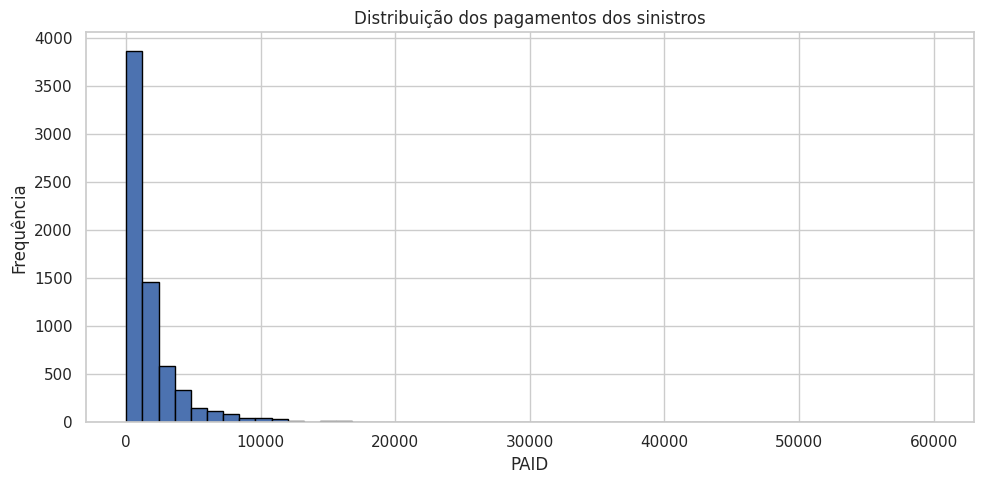

In [ ]:


plt.figure(figsize=(10, 5))

plt.hist(
    dados_analise["PAID"],
    bins=50,
    edgecolor="black"
)

plt.xlabel("PAID")
plt.ylabel("Frequência")
plt.title("Distribuição dos pagamentos dos sinistros")
plt.tight_layout()
plt.show()


**B2 — Distribuição de PAID na escala original**

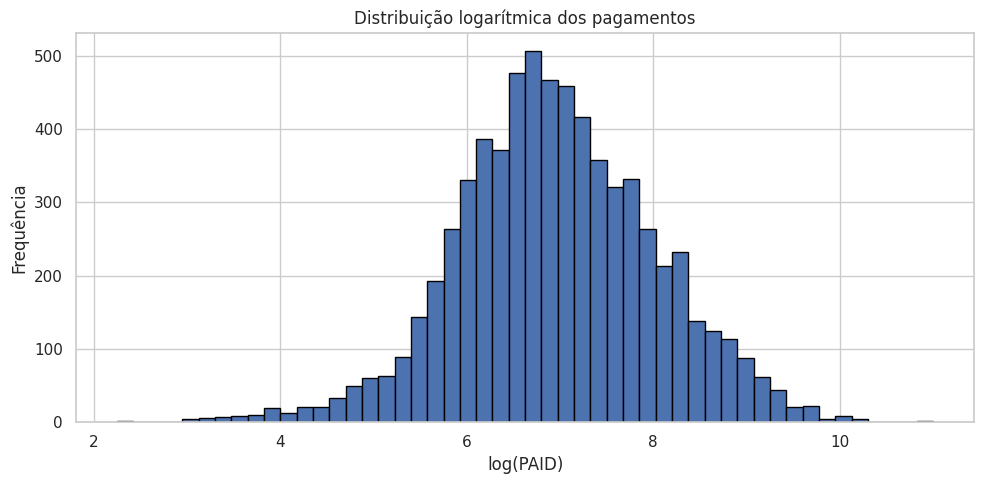

In [ ]:


log_paid = np.log(dados_analise["PAID"])

plt.figure(figsize=(10, 5))

plt.hist(
    log_paid,
    bins=50,
    edgecolor="black"
)

plt.xlabel("log(PAID)")
plt.ylabel("Frequência")
plt.title("Distribuição logarítmica dos pagamentos")
plt.tight_layout()
plt.show()


**B2 — Boxplot dos pagamentos de sinistros (PAID)**

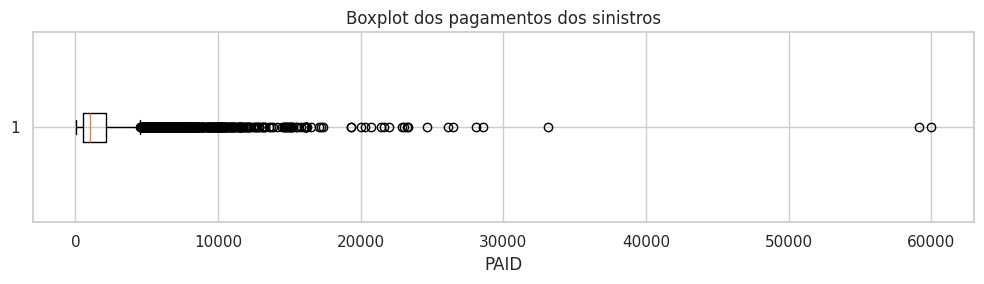

In [ ]:
plt.figure(figsize=(10, 3))

plt.boxplot(
    dados_analise["PAID"],
    vert=False
)

plt.xlabel("PAID")
plt.title("Boxplot dos pagamentos dos sinistros")
plt.tight_layout()
plt.show()


**B2 — Boxplot de PAID**

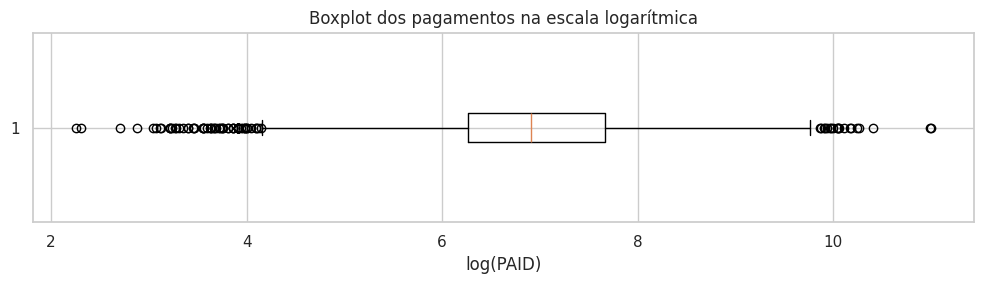

In [ ]:
plt.figure(figsize=(10, 3))

plt.boxplot(
    np.log(dados_analise["PAID"]),
    vert=False
)

plt.xlabel("log(PAID)")
plt.title("Boxplot dos pagamentos na escala logarítmica")
plt.tight_layout()
plt.show()


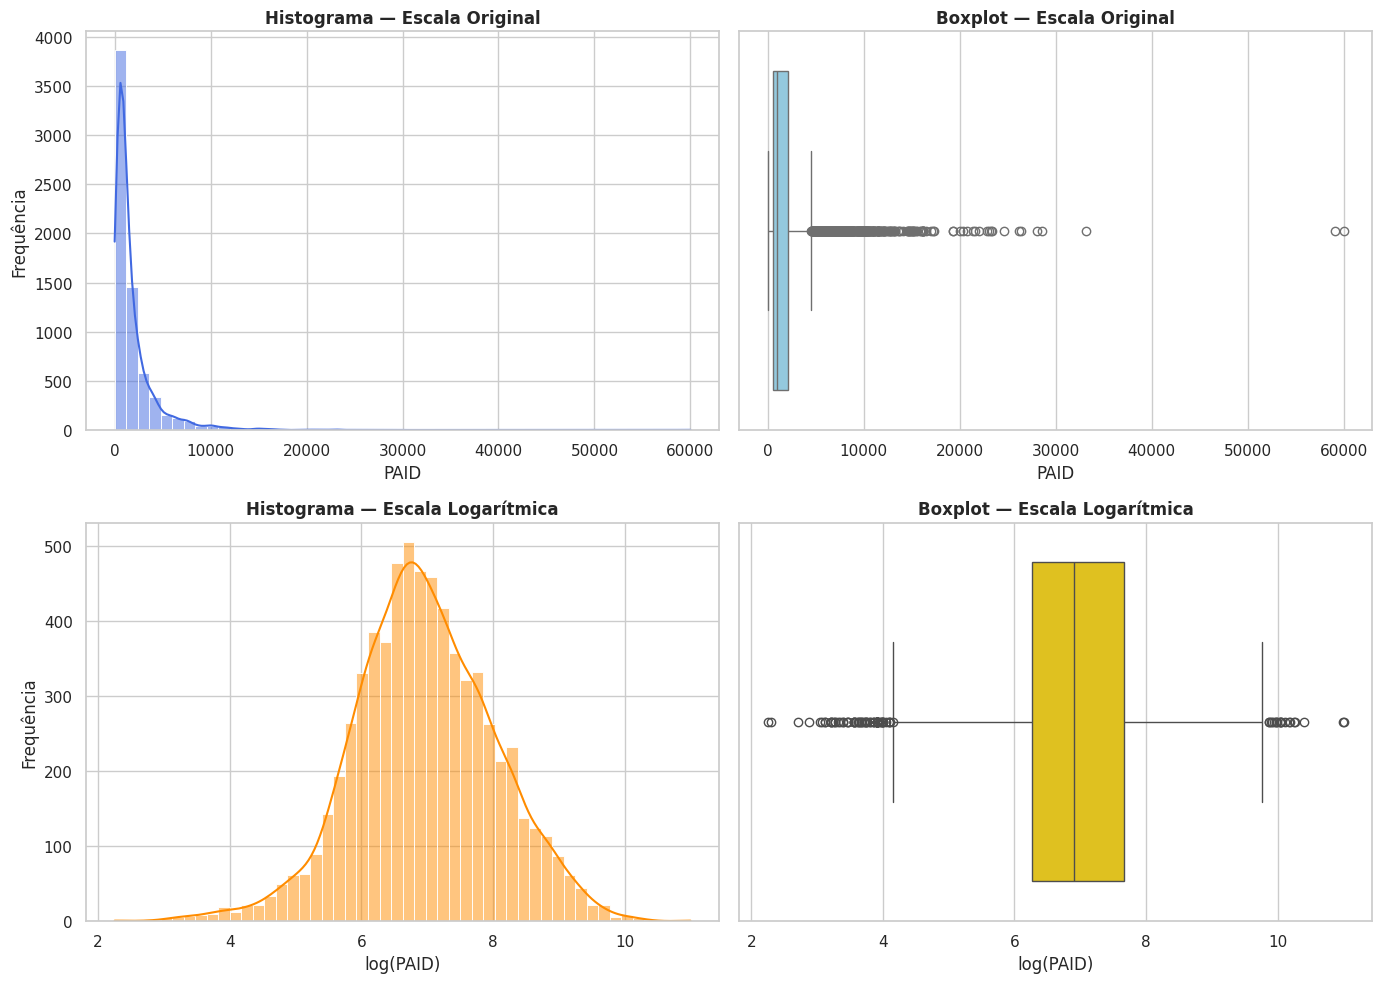

In [ ]:


def plotar_grid_paid(df):

    dados = df.copy()
    dados.columns = dados.columns.str.upper().str.strip()

    paid = dados["PAID"].dropna()
    log_paid = np.log(paid)

    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    sns.histplot(paid, kde=True, ax=axes[0, 0], color='royalblue', bins=50)
    axes[0, 0].set_title('Histograma — Escala Original', fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel('PAID')
    axes[0, 0].set_ylabel('Frequência')

    sns.boxplot(x=paid, ax=axes[0, 1], color='skyblue')
    axes[0, 1].set_title('Boxplot — Escala Original', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('PAID')

    sns.histplot(log_paid, kde=True, ax=axes[1, 0], color='darkorange', bins=50)
    axes[1, 0].set_title('Histograma — Escala Logarítmica', fontsize=12, fontweight='bold')
    axes[1, 0].set_xlabel(r'log(PAID)')
    axes[1, 0].set_ylabel('Frequência')

    sns.boxplot(x=log_paid, ax=axes[1, 1], color='gold')
    axes[1, 1].set_title('Boxplot — Escala Logarítmica', fontsize=12, fontweight='bold')
    axes[1, 1].set_xlabel(r'log(PAID)')

    plt.tight_layout()
    plt.savefig('Dist_Amostral.png')
    plt.show()

plotar_grid_paid(df_raw)

**B3 — Relação entre PAID e idade**

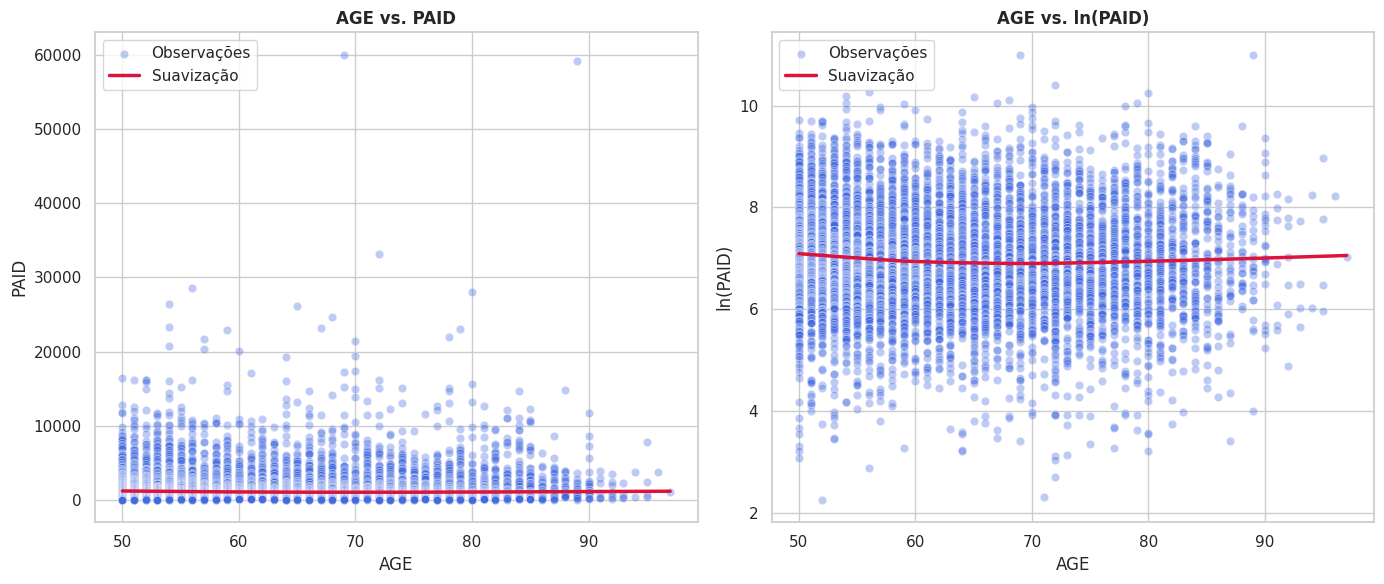

In [ ]:


def plotar_comparativo_escala(df):
    dados = df.copy()
    dados.columns = dados.columns.str.upper().str.strip()

    dados = dados.dropna(subset=["AGE", "PAID"])


    fig, axes = plt.subplots(1, 2, figsize=(14, 6))


    sns.set_theme(style="whitegrid")

    sns.scatterplot(
        x="AGE",
        y="PAID",
        data=dados,
        alpha=0.35,
        color="royalblue",
        ax=axes[0],
        label="Observações"
    )
    sns.regplot(
        x="AGE",
        y="PAID",
        data=dados,
        scatter=False,
        lowess=True,
        color="crimson",
        line_kws={"linewidth": 2.5},
        ax=axes[0],
        label="Suavização"
    )
    axes[0].set_title("AGE vs. PAID", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("AGE")
    axes[0].set_ylabel("PAID")
    axes[0].legend()

    dados["LOG_PAID"] = np.log(dados["PAID"])
    sns.scatterplot(
        x="AGE",
        y="LOG_PAID",
        data=dados,
        alpha=0.35,
        color="royalblue",
        ax=axes[1],
        label="Observações"
    )
    sns.regplot(
        x="AGE",
        y="LOG_PAID",
        data=dados,
        scatter=False,
        lowess=True,
        color="crimson",
        line_kws={"linewidth": 2.5},
        ax=axes[1],
        label="Suavização"
    )
    axes[1].set_title("AGE vs. ln(PAID)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("AGE")
    axes[1].set_ylabel("ln(PAID)")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig('age_x_paid')
    plt.show()

plotar_comparativo_escala(df_raw)

resumo idade

**B3 — Resumo descritivo da idade**

In [ ]:
resumo_idade = (
    dados_analise
    .groupby("AGE", observed=True)["PAID"]
    .agg(
        media="mean",
        mediana="median",
        n="count"
    )
    .reset_index()
)

print(resumo_idade)


    AGE        media   mediana    n
0    50  1905.504036  1160.165  446
1    51  1992.740747  1150.745  348
2    52  1868.323112  1045.280  331
3    53  1810.499458  1074.510  295
4    54  2240.885615  1100.940  301
5    55  1801.050346  1080.920  289
6    56  1909.005885   935.740  243
7    57  1697.499142   972.950  233
8    58  1726.151198  1042.500  217
9    59  1828.427277   999.995  224
10   60  1612.725749   947.840  207
11   61  1661.881762   981.570  193
12   62  1774.267588  1068.865  170
13   63  1635.638305   903.990  177
14   64  1973.371011  1067.960  178
15   65  1584.309563   863.830  183
16   66  1875.746092   926.125  174
17   67  1792.315000   932.875  160
18   68  1936.354231   964.925  156
19   69  1977.356685   902.100  181
20   70  2102.721250   956.460  144
21   71  1730.840506   956.660  158
22   72  1852.757836   939.240  171
23   73  1514.090994   843.690  161
24   74  1942.253101  1100.000  129
25   75  1407.182336   818.010  137
26   76  1402.726614   885.3

**B3 — Gráfico de PAID em função da idade**

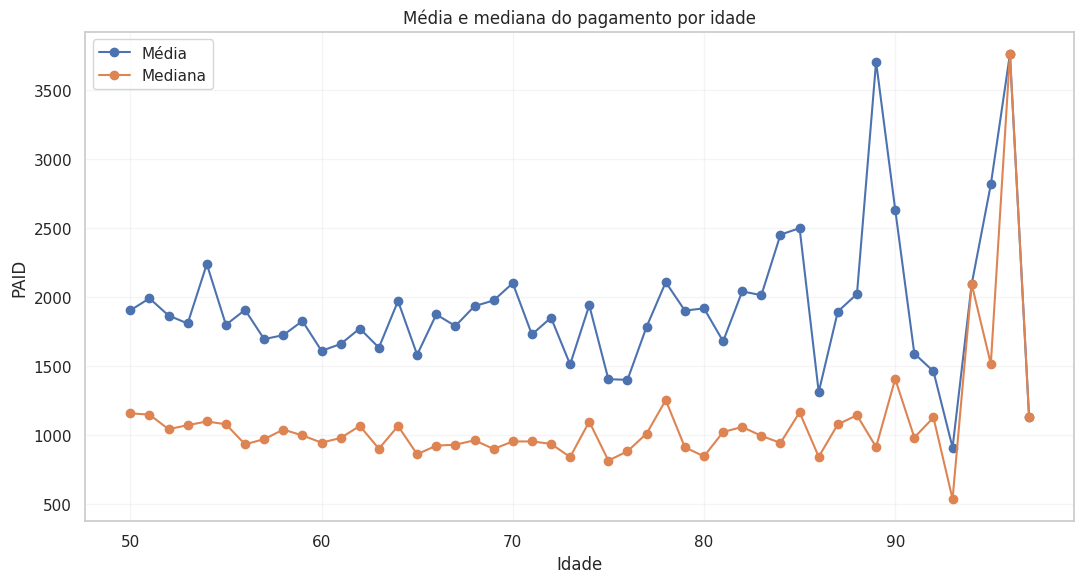

In [ ]:
plt.figure(figsize=(11, 6))

plt.plot(
    resumo_idade["AGE"],
    resumo_idade["media"],
    marker="o",
    label="Média"
)

plt.plot(
    resumo_idade["AGE"],
    resumo_idade["mediana"],
    marker="o",
    label="Mediana"
)

plt.xlabel("Idade")
plt.ylabel("PAID")
plt.title("Média e mediana do pagamento por idade")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()




**B3 — Verificação da variabilidade de PAID em função da idade**

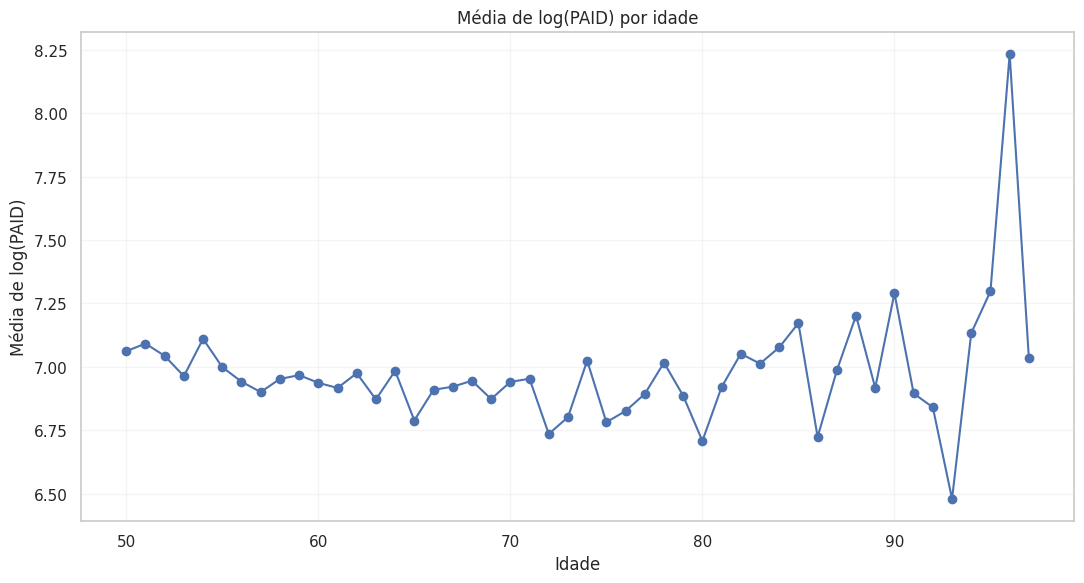

In [ ]:
resumo_idade["media_log_paid"] = (
    dados_analise
    .assign(log_PAID=np.log(dados_analise["PAID"]))
    .groupby("AGE", observed=True)["log_PAID"]
    .mean()
    .values
)

plt.figure(figsize=(11, 6))

plt.plot(
    resumo_idade["AGE"],
    resumo_idade["media_log_paid"],
    marker="o"
)

plt.xlabel("Idade")
plt.ylabel("Média de log(PAID)")
plt.title("Média de log(PAID) por idade")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**B4 — Comparação da distribuição de PAID entre os níveis de GENDER**

In [ ]:
resumo_gender = (
    dados_analise
    .groupby("GENDER", observed=True)["PAID"]
    .agg(
        n="count",
        media="mean",
        mediana="median",
        desvio_padrao="std",
        minimo="min",
        maximo="max"
    )
)

resumo_gender["coef_variacao_%"] = (
    resumo_gender["desvio_padrao"] /
    resumo_gender["media"] * 100
)

print(resumo_gender.round(2))


           n    media  mediana  desvio_padrao  minimo    maximo  \
GENDER                                                            
M       4191  1846.58  1031.69        2574.69     9.5  59113.78   
F       2582  1863.50   963.30        2760.58    10.0  60000.00   

        coef_variacao_%  
GENDER                   
M                139.43  
F                148.14  


**B4 — Distribuição de PAID por STATE**

In [ ]:
resumo_state = (
    dados_analise
    .groupby("STATE", observed=True)["PAID"]
    .agg(
        n="count",
        media="mean",
        mediana="median",
        desvio_padrao="std",
        minimo="min",
        maximo="max"
    )
)

resumo_state["coef_variacao_%"] = (
    resumo_state["desvio_padrao"] /
    resumo_state["media"] * 100
)

print(resumo_state.round(2))


             n    media  mediana  desvio_padrao  minimo    maximo  \
STATE                                                               
STATE 15  2180  1767.52   970.90        2340.10    9.50  28083.99   
STATE 01   166  1574.46   962.79        1985.39   25.00  15845.00   
STATE 02  1122  1775.65   969.58        2334.61   10.00  23231.54   
STATE 03   348  1830.10   835.97        2992.11   44.97  23344.38   
STATE 04   666  1744.33   957.26        2707.82   20.93  28593.49   
STATE 06   622  2089.64  1202.72        2438.79   61.34  19348.67   
STATE 07   269  1942.78   906.62        4116.61   26.23  60000.00   
STATE 10   276  1886.48  1129.58        2307.59   50.00  21404.96   
STATE 11     9  1682.73  1450.00        1463.48  146.11   4635.00   
STATE 12   247  2384.73  1294.87        2685.46   25.00  16161.53   
STATE 13   208  2029.09  1130.38        3138.08   55.00  33137.50   
STATE 14   169  1648.90  1000.03        2628.33   60.00  26439.48   
STATE 17   491  2031.05  1101.36  

/tmp/ipykernel_888/81785862.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ordem_mediana = dados.groupby(var_cat)["LOG_RESP"].median().sort_values(ascending=False).index
/tmp/ipykernel_888/81785862.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


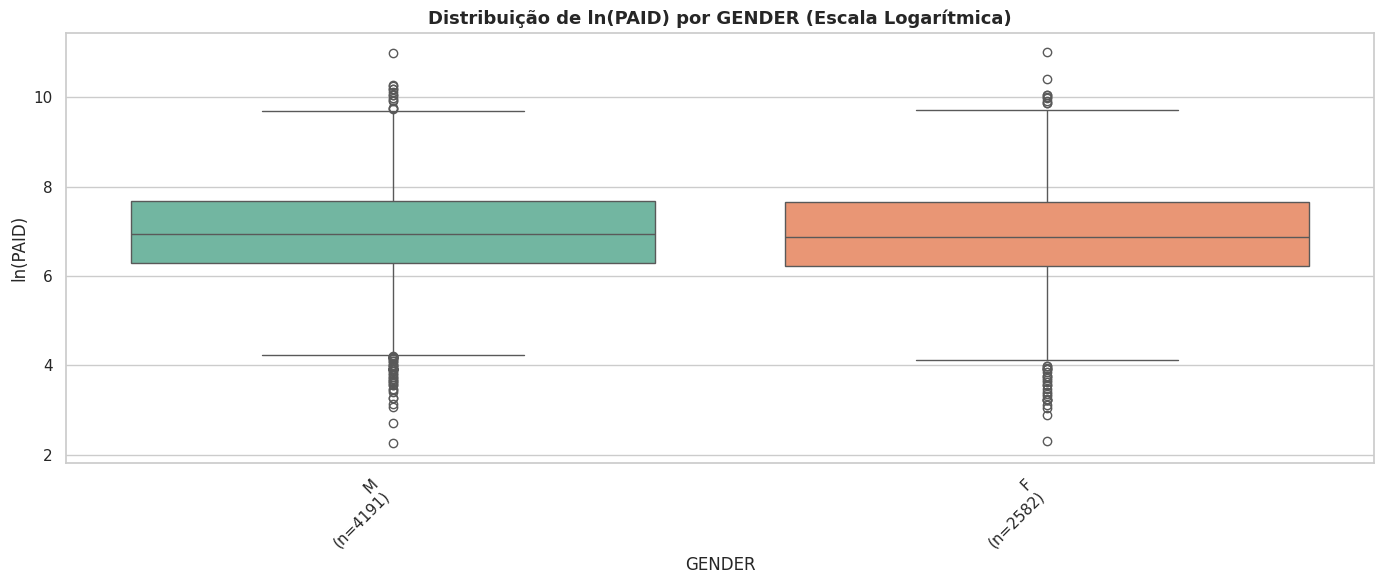

In [ ]:


def plotar_boxplot_log_com_n(df, var_cat, var_resp="PAID"):

    dados = df.copy()
    dados.columns = dados.columns.str.upper().str.strip()

    dados["LOG_RESP"] = np.log(dados[var_resp])

    counts = dados[var_cat].value_counts()

    ordem_mediana = dados.groupby(var_cat)["LOG_RESP"].median().sort_values(ascending=False).index

    labels_com_n = [f"{cat}\n(n={counts[cat]})" for cat in ordem_mediana]

    plt.figure(figsize=(14, 6))
    sns.set_theme(style="whitegrid")

    sns.boxplot(
        x=var_cat,
        y="LOG_RESP",
        data=dados,
        order=ordem_mediana,
        palette="Set2"
    )

    plt.title(f"Distribuição de ln({var_resp}) por {var_cat} (Escala Logarítmica)", fontsize=13, fontweight="bold")
    plt.xlabel(var_cat)
    plt.ylabel(f"ln({var_resp})")
    plt.xticks(ticks=range(len(ordem_mediana)), labels=labels_com_n, rotation=45, ha="right")

    plt.tight_layout()
    plt.savefig('Boxplot_GENDER')
    plt.show()


plotar_boxplot_log_com_n(df_raw, "GENDER", "PAID")

<Figure size 800x600 with 0 Axes>

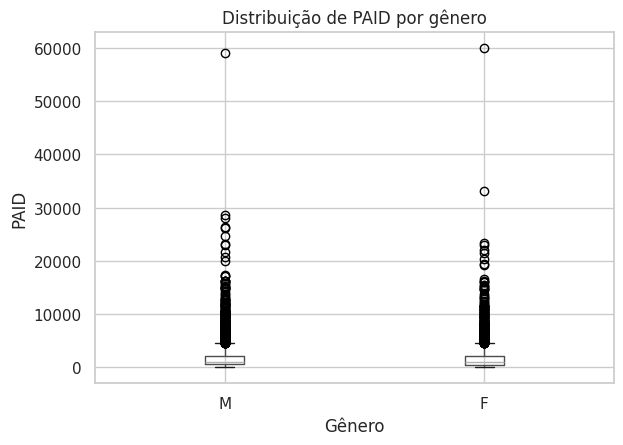

In [ ]:
plt.figure(figsize=(8, 6))

dados_analise.boxplot(
    column="PAID",
    by="GENDER"
)

plt.xlabel("Gênero")
plt.ylabel("PAID")
plt.title("Distribuição de PAID por gênero")
plt.suptitle("")
plt.tight_layout()
plt.show()


**B4 — Boxplot de PAID por STATE**

<Figure size 1400x700 with 0 Axes>

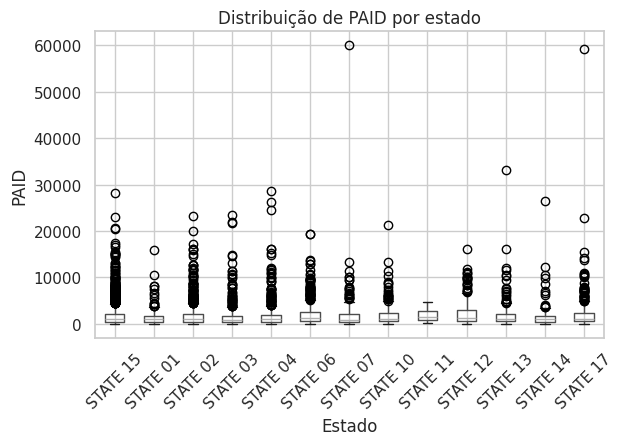

In [ ]:
plt.figure(figsize=(14, 7))

dados_analise.boxplot(
    column="PAID",
    by="STATE",
    rot=45
)

plt.xlabel("Estado")
plt.ylabel("PAID")
plt.title("Distribuição de PAID por estado")
plt.suptitle("")
plt.tight_layout()
plt.show()


**B4 — Distribuição de log(PAID) por STATE**

<Figure size 1400x700 with 0 Axes>

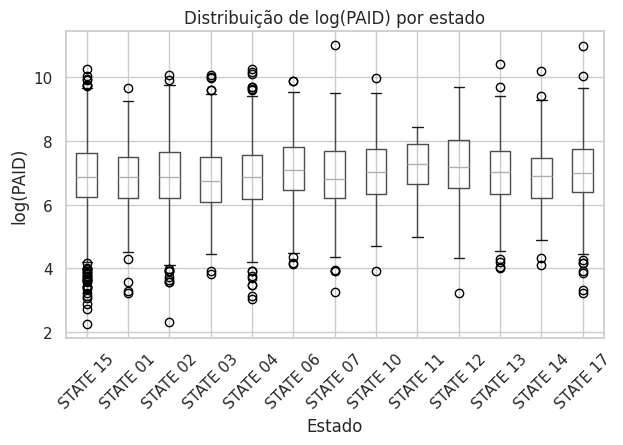

In [ ]:
dados_plot = dados_analise.copy()
dados_plot["log_PAID"] = np.log(dados_plot["PAID"])

plt.figure(figsize=(14, 7))

dados_plot.boxplot(
    column="log_PAID",
    by="STATE",
    rot=45
)

plt.xlabel("Estado")
plt.ylabel("log(PAID)")
plt.title("Distribuição de log(PAID) por estado")
plt.suptitle("")
plt.tight_layout()
plt.show()


**B5 — Distribuição das frequências entre as classes tarifárias (CLASS)**

In [ ]:
frequencia_class = (
    dados_analise["CLASS"]
    .value_counts()
    .sort_values(ascending=False)
    .to_frame("n")
)

frequencia_class["percentual"] = (
    frequencia_class["n"] / len(dados_analise) * 100
)

print(frequencia_class.round(2))


          n  percentual
CLASS                  
C11    1151       16.99
C71    1129       16.67
C7      913       13.48
C6      911       13.45
C1      726       10.72
C7B     686       10.13
C1B     424        6.26
F6      157        2.32
C7A     113        1.67
F71      93        1.37
C72      85        1.25
C7C      81        1.20
C1A      77        1.14
C2       61        0.90
F7       59        0.87
F11      40        0.59
C1C      38        0.56
F1       29        0.43


**B5 — Gráfico de frequência das classes tarifárias**

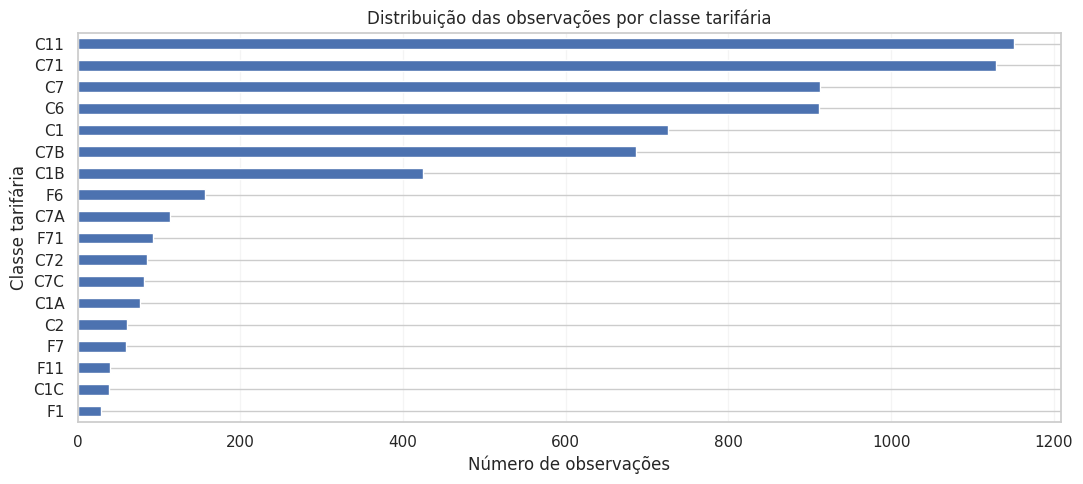

In [ ]:
plt.figure(figsize=(11, 5))

frequencia_class["n"].sort_values().plot(
    kind="barh"
)

plt.xlabel("Número de observações")
plt.ylabel("Classe tarifária")
plt.title("Distribuição das observações por classe tarifária")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.savefig('observações_CLASS')
plt.show()


**B5 — Identificação das classes tarifárias com menor frequência**

In [ ]:
print("Cinco classes com menor frequência:")
print(frequencia_class.sort_values("n").head(5))


Cinco classes com menor frequência:
        n  percentual
CLASS                
F1     29    0.428171
C1C    38    0.561051
F11    40    0.590580
F7     59    0.871106
C2     61    0.900635


PARTE C

**C1 — Centralização da variável AGE**

In [ ]:
media_age = dados_analise["AGE"].mean()

dados_analise["AGEc"] = (
    dados_analise["AGE"] - media_age
)

print(f"Média da idade: {media_age:.4f}")
print(f"Média de AGEc: {dados_analise['AGEc'].mean():.10f}")


Média da idade: 63.8115
Média de AGEc: 0.0000000000


**C3 — Definição das estruturas candidatas de modelagem**

In [ ]:
estruturas = {
    "M0": "PAID ~ 1",
    "M1": "PAID ~ AGEc + GENDER",
    "M2": "PAID ~ AGEc + GENDER + STATE",
    "M3": "PAID ~ CLASS + STATE",
    "M4": "PAID ~ AGEc + GENDER + CLASS + STATE"
}

for modelo, formula in estruturas.items():
    print(f"{modelo}: {formula}")


M0: PAID ~ 1
M1: PAID ~ AGEc + GENDER
M2: PAID ~ AGEc + GENDER + STATE
M3: PAID ~ CLASS + STATE
M4: PAID ~ AGEc + GENDER + CLASS + STATE


**D1 — Ajuste dos modelos Normal, Gama e Gaussiano inverso**

In [ ]:
formula_m1 = "PAID ~ AGEc + C(GENDER, Treatment(reference='M'))"

modelo_normal = smf.glm(
    formula=formula_m1,
    data=dados_analise,
    family=sm.families.Gaussian(
        link=sm.families.links.Log()
    )
).fit()

modelo_gama = smf.glm(
    formula=formula_m1,
    data=dados_analise,
    family=sm.families.Gamma(
        link=sm.families.links.Log()
    )
).fit()

modelo_inverse_gaussian = smf.glm(
    formula=formula_m1,
    data=dados_analise,
    family=sm.families.InverseGaussian(
        link=sm.families.links.Log()
    )
).fit()

print("Modelos ajustados:")
print("Normal:", modelo_normal.converged)
print("Gama:", modelo_gama.converged)
print("Gaussiano inverso:", modelo_inverse_gaussian.converged)


Modelos ajustados:
Normal: True
Gama: True
Gaussiano inverso: True


**D4 — Comparação inicial das três famílias de distribuição**

In [ ]:
modelos = {
    "Normal": modelo_normal,
    "Gama": modelo_gama,
    "Gaussiano inverso": modelo_inverse_gaussian
}

comparacao = pd.DataFrame({
    "Log-verossimilhança": {
        nome: modelo.llf
        for nome, modelo in modelos.items()
    },
    "AIC": {
        nome: modelo.aic
        for nome, modelo in modelos.items()
    },
    "BIC": {
        nome: modelo.bic_llf
        for nome, modelo in modelos.items()
    }
})

comparacao["Delta_AIC"] = (
    comparacao["AIC"] - comparacao["AIC"].min()
)

pesos = np.exp(-comparacao["Delta_AIC"] / 2)
comparacao["Peso_Akaike"] = pesos / pesos.sum()

comparacao = comparacao.sort_values("AIC")

print(comparacao.round(4))


                   Log-verossimilhança          AIC          BIC   Delta_AIC  \
Gaussiano inverso          -57658.8211  115323.6421  115344.1042      0.0000   
Gama                       -58688.4115  117382.8231  117403.2852   2059.1810   
Normal                     -62988.8921  125983.7842  126004.2463  10660.1421   

                   Peso_Akaike  
Gaussiano inverso          1.0  
Gama                       0.0  
Normal                     0.0  


**D2 — Tabela de coeficientes dos modelos Normal, Gama e Gaussiano inverso**

In [ ]:
def tabela_coeficientes(modelo, nome_modelo):
    tabela = pd.DataFrame({
        "Estimativa": modelo.params,
        "Erro_padrao": modelo.bse,
        "IC_95_inf": modelo.conf_int()[0],
        "IC_95_sup": modelo.conf_int()[1],
        "p_valor": modelo.pvalues
    })

    tabela["Modelo"] = nome_modelo

    return tabela.reset_index().rename(columns={"index": "Termo"})


coeficientes = pd.concat([
    tabela_coeficientes(modelo_normal, "Normal"),
    tabela_coeficientes(modelo_gama, "Gama"),
    tabela_coeficientes(modelo_inverse_gaussian, "Gaussiano inverso")
])

print(coeficientes.round(4).to_string(index=False))


                                   Termo  Estimativa  Erro_padrao  IC_95_inf  IC_95_sup  p_valor            Modelo
                               Intercept      7.5212       0.0221     7.4778     7.5646   0.0000            Normal
C(GENDER, Treatment(reference='M'))[T.F]      0.0089       0.0357    -0.0610     0.0788   0.8027            Normal
                                    AGEc      0.0006       0.0016    -0.0026     0.0038   0.7191            Normal
                               Intercept      7.5211       0.0220     7.4779     7.5643   0.0000              Gama
C(GENDER, Treatment(reference='M'))[T.F]      0.0090       0.0357    -0.0610     0.0789   0.8011              Gama
                                    AGEc      0.0005       0.0016    -0.0027     0.0037   0.7452              Gama
                               Intercept      7.5211       0.0220     7.4780     7.5642   0.0000 Gaussiano inverso
C(GENDER, Treatment(reference='M'))[T.F]      0.0090       0.0357    -0.0610    

**D3 — Interpretação dos coeficientes dos modelos**

In [ ]:
interpretacao = []

for nome, modelo in modelos.items():

    beta_age = modelo.params["AGEc"]
    beta_gender = modelo.params["C(GENDER, Treatment(reference='M'))[T.F]"]

    interpretacao.append({
        "Modelo": nome,
        "exp(beta_age)": np.exp(beta_age),
        "Efeito_age_%": 100 * (np.exp(beta_age) - 1),
        "exp(beta_gender_F)": np.exp(beta_gender),
        "Efeito_gender_F_%": 100 * (np.exp(beta_gender) - 1)
    })

interpretacao = pd.DataFrame(interpretacao)

print(interpretacao.round(4).to_string(index=False))


           Modelo  exp(beta_age)  Efeito_age_%  exp(beta_gender_F)  Efeito_gender_F_%
           Normal         1.0006        0.0583              1.0090             0.8952
             Gama         1.0005        0.0528              1.0090             0.9030
Gaussiano inverso         1.0005        0.0504              1.0091             0.9060


**D1 — Ajuste do modelo Gaussiano inverso**

In [ ]:
formulas = {
     "M1": "PAID ~ AGEc + C(GENDER, Treatment(reference='M'))",
     "M2": "PAID ~ AGEc + C(GENDER, Treatment(reference='M')) + C(STATE, Treatment(reference='STATE 15'))",
     "M3": "PAID ~ C(CLASS, Treatment(reference='C11')) + C(STATE, Treatment(reference='STATE 15'))",
     "M4": "PAID ~ AGEc + C(GENDER, Treatment(reference='M')) + C(CLASS, Treatment(reference='C11')) + C(STATE, Treatment(reference='STATE 15'))"
 }

modelos_estrutura = {}

for nome, formula in formulas.items():
    modelo = smf.glm(
        formula=formula,
        data=dados_analise,
        family=sm.families.InverseGaussian(
            link=sm.families.links.Log()
        )
    ).fit()

    modelos_estrutura[nome] = modelo

    print(f"{nome}: convergiu = {modelo.converged}")


M1: convergiu = True
M2: convergiu = True
M3: convergiu = True
M4: convergiu = True


**D5 — Comparação das estruturas candidatas de modelagem**

In [ ]:
comparacao_estruturas = pd.DataFrame({
    "Log-verossimilhança": {
        nome: modelo.llf
        for nome, modelo in modelos_estrutura.items()
    },
    "AIC": {
        nome: modelo.aic
        for nome, modelo in modelos_estrutura.items()
    },
    "BIC": {
        nome: modelo.bic_llf
        for nome, modelo in modelos_estrutura.items()
    }
})

comparacao_estruturas["Delta_AIC"] = (
    comparacao_estruturas["AIC"] -
    comparacao_estruturas["AIC"].min()
)

pesos = np.exp(-comparacao_estruturas["Delta_AIC"] / 2)

comparacao_estruturas["Peso_Akaike"] = (
    pesos / pesos.sum()
)

comparacao_estruturas = comparacao_estruturas.sort_values("AIC")

print(comparacao_estruturas.round(4))


    Log-verossimilhança          AIC          BIC  Delta_AIC  Peso_Akaike
M1          -57658.8211  115323.6421  115344.1042     0.0000       0.8283
M2          -57648.4051  115326.8103  115429.1208     3.1681       0.1699
M3          -57637.9945  115335.9889  115540.6099    12.3468       0.0017
M4          -57640.8427  115345.6854  115563.9478    22.0433       0.0000


**D5 — Comparação dos coeficientes dos modelos M3 e M4**

In [ ]:
for nome in ["M3", "M4"]:
    print("\n" + "=" * 60)
    print(nome)
    print("=" * 60)

    tabela = pd.DataFrame({
        "Estimativa": modelos_estrutura[nome].params,
        "Erro_padrao": modelos_estrutura[nome].bse,
        "IC_95_inf": modelos_estrutura[nome].conf_int()[0],
        "IC_95_sup": modelos_estrutura[nome].conf_int()[1],
        "p_valor": modelos_estrutura[nome].pvalues
    })

    print(tabela.round(4))



M3
                                                    Estimativa  Erro_padrao  \
Intercept                                               7.4699       0.0477   
C(CLASS, Treatment(reference='C11'))[T.C1]             -0.0262       0.0673   
C(CLASS, Treatment(reference='C11'))[T.C1A]            -0.0795       0.1631   
C(CLASS, Treatment(reference='C11'))[T.C1B]             0.0063       0.0820   
C(CLASS, Treatment(reference='C11'))[T.C1C]            -0.2695       0.2045   
C(CLASS, Treatment(reference='C11'))[T.C2]             -0.3549       0.1607   
C(CLASS, Treatment(reference='C11'))[T.C6]              0.0140       0.0632   
C(CLASS, Treatment(reference='C11'))[T.C7]             -0.0462       0.0624   
C(CLASS, Treatment(reference='C11'))[T.C71]            -0.0262       0.0597   
C(CLASS, Treatment(reference='C11'))[T.C72]             0.1870       0.1732   
C(CLASS, Treatment(reference='C11'))[T.C7A]            -0.0007       0.1403   
C(CLASS, Treatment(reference='C11'))[T.C7B]     

**E1 — Preparação dos resíduos dos modelos Normal, Gama e Gaussiano inverso**

In [ ]:
residuos = {}

for nome, modelo in modelos.items():
    residuos[nome] = pd.DataFrame({
        "AGE": dados_analise["AGE"].values,
        "PAID": dados_analise["PAID"].values,
        "ajustado": modelo.fittedvalues.values,
        "resid_pearson": modelo.resid_pearson,
        "resid_deviance": modelo.resid_deviance
    })

print("Resíduos preparados com sucesso.\n")

for nome, tabela in residuos.items():
    print(f"{nome}: {len(tabela)} observações")


Resíduos preparados com sucesso.

Normal: 6773 observações
Gama: 6773 observações
Gaussiano inverso: 6773 observações


**E1 — Resíduos de Pearson versus valores ajustados**

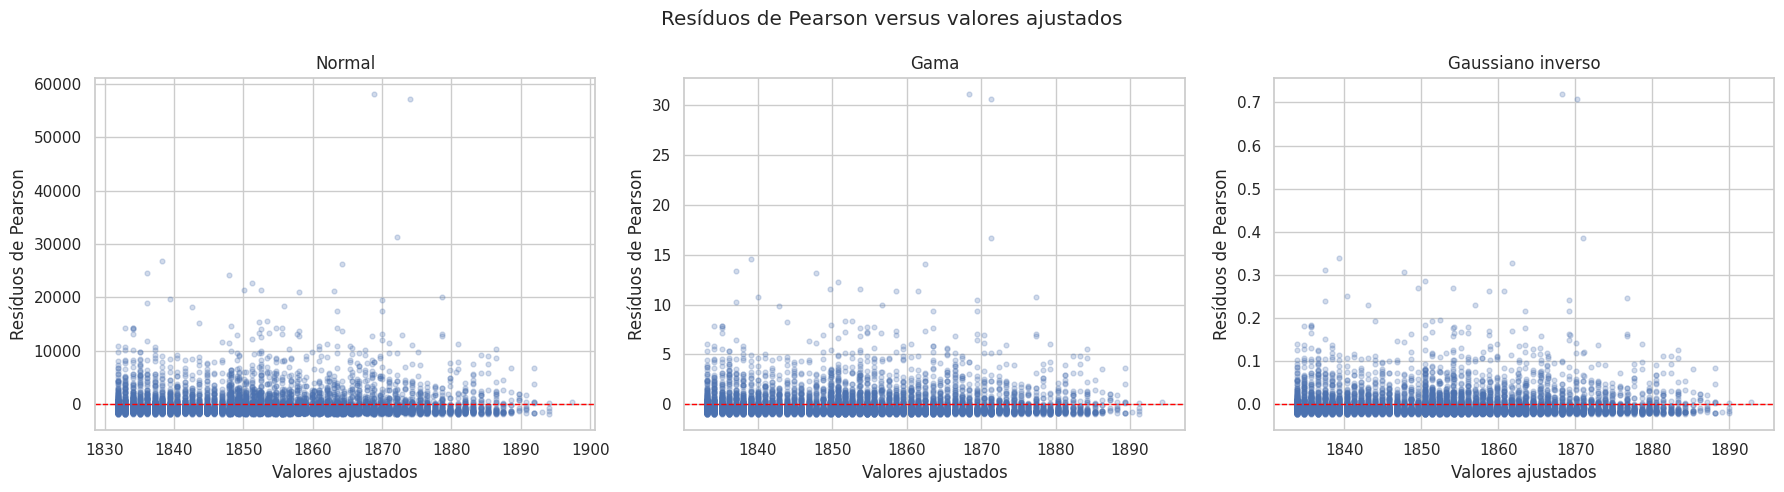

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, nome in zip(axes, ["Normal", "Gama", "Gaussiano inverso"]):
    ax.scatter(
        residuos[nome]["ajustado"],
        residuos[nome]["resid_pearson"],
        alpha=0.25,
        s=12
    )

    ax.axhline(0, color="red", linestyle="--", linewidth=1)

    ax.set_title(nome)
    ax.set_xlabel("Valores ajustados")
    ax.set_ylabel("Resíduos de Pearson")

plt.suptitle("Resíduos de Pearson versus valores ajustados")
plt.tight_layout()
plt.savefig('Res_ajustado')
plt.show()


**E1 — Resíduos de Pearson versus idade**

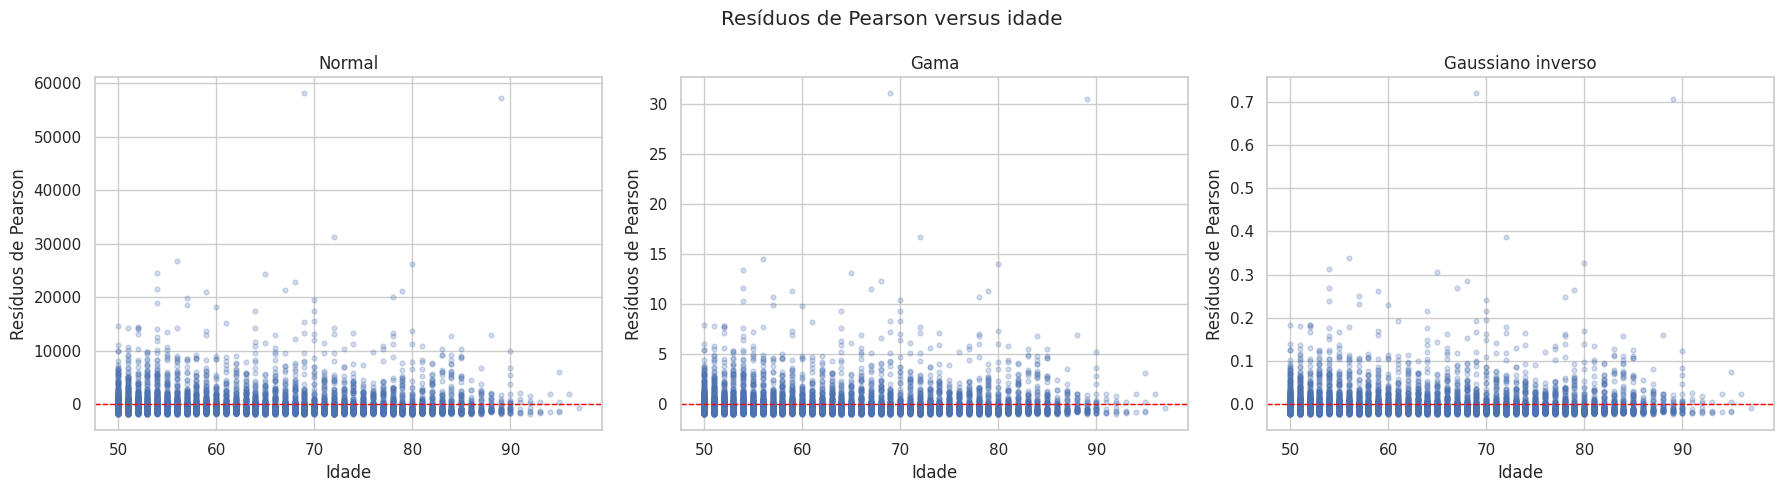

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, nome in zip(axes, ["Normal", "Gama", "Gaussiano inverso"]):
    ax.scatter(
        residuos[nome]["AGE"],
        residuos[nome]["resid_pearson"],
        alpha=0.25,
        s=12
    )

    ax.axhline(
        0,
        color="red",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(nome)
    ax.set_xlabel("Idade")
    ax.set_ylabel("Resíduos de Pearson")

plt.suptitle("Resíduos de Pearson versus idade")
plt.tight_layout()
plt.savefig('Res_idade')
plt.show()


**E1 — Gráfico Q–Q dos resíduos de desvio padronizados**

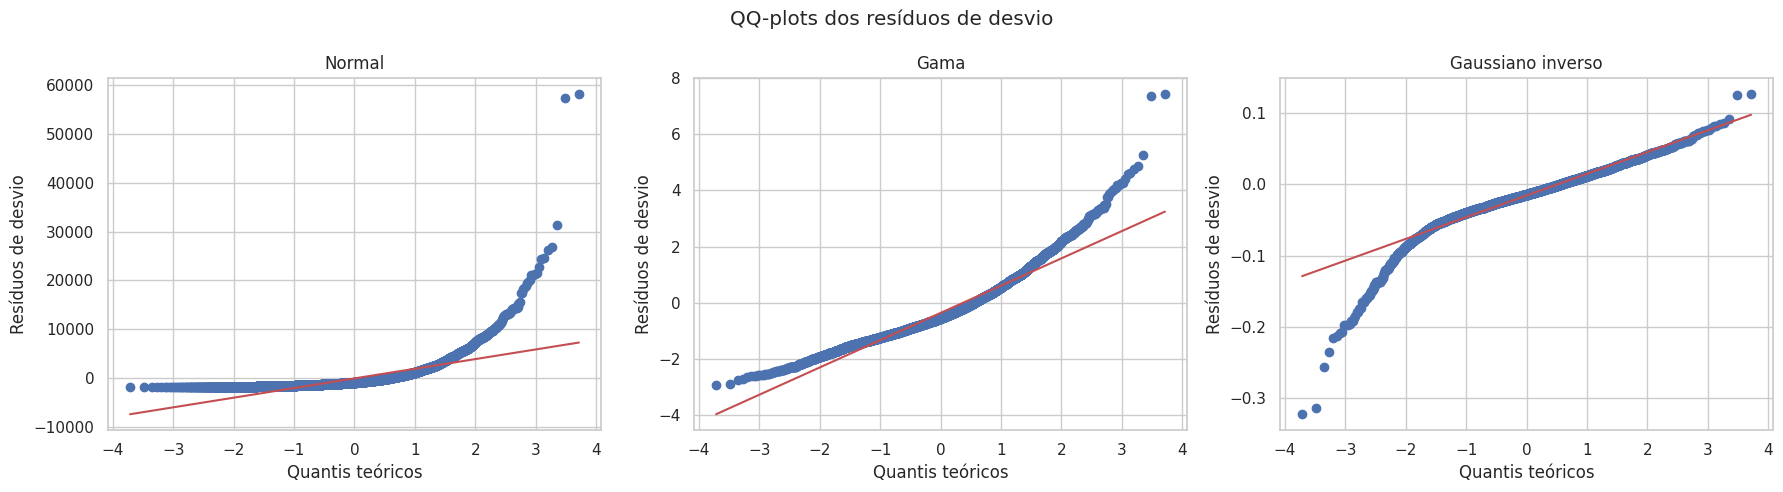

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, nome in zip(
    axes,
    ["Normal", "Gama", "Gaussiano inverso"]
):

    stats.probplot(
        residuos[nome]["resid_deviance"],
        dist="norm",
        plot=ax
    )

    ax.set_title(nome)
    ax.set_xlabel("Quantis teóricos")
    ax.set_ylabel("Resíduos de desvio")

plt.suptitle("QQ-plots dos resíduos de desvio")
plt.tight_layout()
plt.savefig('QQ_res')
plt.show()


**E3 — Identificação de observações com alta alavancagem**

In [ ]:
alavancagens = {}

for nome, modelo in modelos.items():

    X = modelo.model.exog
    mu = modelo.fittedvalues.values

    variancia = modelo.family.variance(mu)
    derivada = modelo.family.link.deriv(mu)

    pesos = 1 / (
        variancia * derivada**2
    )

    Xw = X * np.sqrt(pesos)[:, None]

    XtWX = Xw.T @ Xw

    XtWX_inv = np.linalg.pinv(XtWX)

    hii = np.sum(
        (Xw @ XtWX_inv) * Xw,
        axis=1
    )

    alavancagens[nome] = hii

    print(
        f"{nome}: "
        f"mínimo = {hii.min():.6f}, "
        f"máximo = {hii.max():.6f}, "
        f"média = {hii.mean():.6f}"
    )


Normal: mínimo = 0.000239, máximo = 0.001712, média = 0.000443
Gama: mínimo = 0.000239, máximo = 0.001677, média = 0.000443
Gaussiano inverso: mínimo = 0.000239, máximo = 0.001663, média = 0.000443


**E1 — Cálculo dos resíduos de desvio padronizados**

In [ ]:
for nome in modelos.keys():

    residuos[nome]["alavancagem"] = alavancagens[nome]

    residuos[nome]["resid_deviance_padronizado"] = (
        residuos[nome]["resid_deviance"]
        /
        np.sqrt(1 - residuos[nome]["alavancagem"])
    )

print("Resíduos de desvio padronizados calculados.")


Resíduos de desvio padronizados calculados.


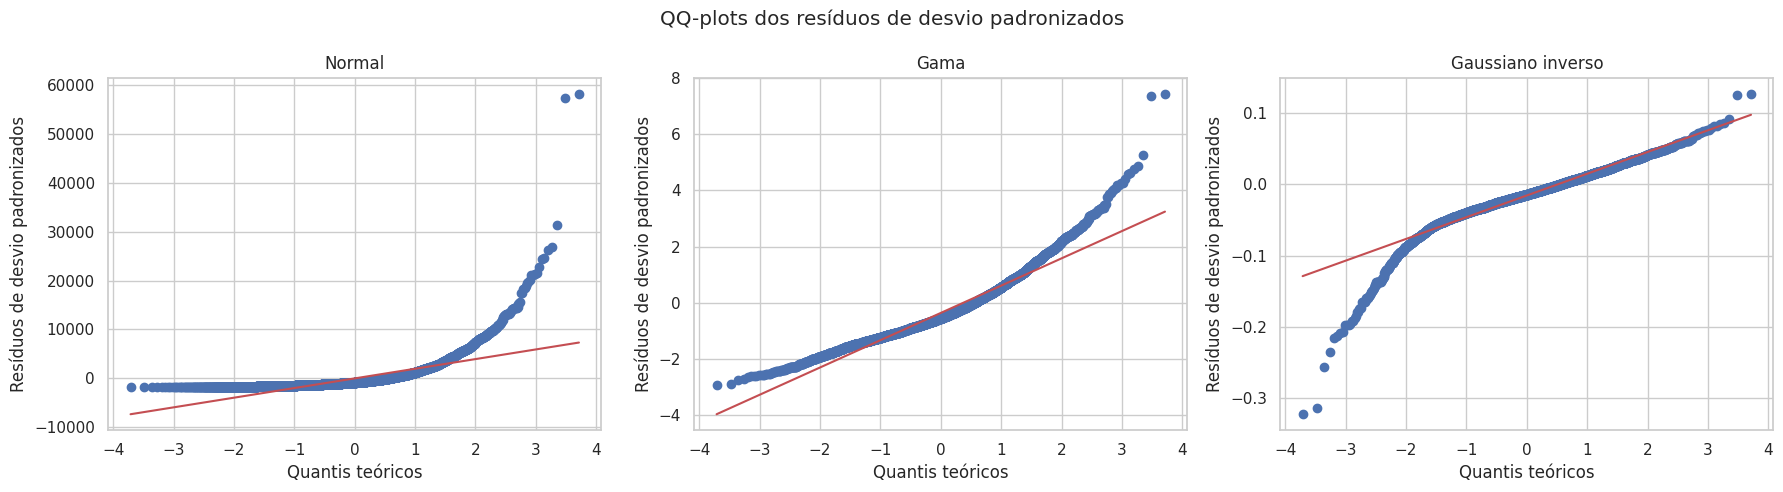

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, nome in zip(
    axes,
    ["Normal", "Gama", "Gaussiano inverso"]
):

    stats.probplot(
        residuos[nome]["resid_deviance_padronizado"],
        dist="norm",
        plot=ax
    )

    ax.set_title(nome)
    ax.set_xlabel("Quantis teóricos")
    ax.set_ylabel("Resíduos de desvio padronizados")

plt.suptitle(
    "QQ-plots dos resíduos de desvio padronizados"
)

plt.tight_layout()
plt.show()


**E2 — Resumo dos resíduos dos modelos**

In [ ]:
resumo_residuos = []

for nome in modelos.keys():

    r_pearson = residuos[nome]["resid_pearson"]
    r_dev = residuos[nome]["resid_deviance_padronizado"]

    resumo_residuos.append({
        "Modelo": nome,
        "Media_Pearson": r_pearson.mean(),
        "DP_Pearson": r_pearson.std(),
        "Min_Pearson": r_pearson.min(),
        "Max_Pearson": r_pearson.max(),
        "Media_Dev_Padronizado": r_dev.mean(),
        "DP_Dev_Padronizado": r_dev.std(),
        "Min_Dev_Padronizado": r_dev.min(),
        "Max_Dev_Padronizado": r_dev.max()
    })

resumo_residuos = pd.DataFrame(resumo_residuos)

print(resumo_residuos.round(4).to_string(index=False))


           Modelo  Media_Pearson  DP_Pearson  Min_Pearson  Max_Pearson  Media_Dev_Padronizado  DP_Dev_Padronizado  Min_Dev_Padronizado  Max_Dev_Padronizado
           Normal         0.0017   2646.8726   -1861.0534   58131.1279                 0.0088           2647.5187           -1861.4745           58143.3560
             Gama        -0.0000      1.4261      -0.9948      31.1125                -0.3652              1.0026              -2.9225               7.4370
Gaussiano inverso         0.0000      0.0331      -0.0232       0.7199                -0.0156              0.0317              -0.3228               0.1271


**E2 — Dispersão dos resíduos em função dos valores ajustados**

In [ ]:
resumo_faixas = {}

for nome in modelos.keys():

    tabela = residuos[nome].copy()

    tabela["faixa_ajustado"] = pd.qcut(
        tabela["ajustado"],
        q=10,
        duplicates="drop"
    )

    resumo = (
        tabela
        .groupby("faixa_ajustado", observed=True)
        .agg(
            media_ajustado=("ajustado", "mean"),
            media_residuo=("resid_pearson", "mean"),
            dp_residuo=("resid_pearson", "std"),
            n=("resid_pearson", "size")
        )
        .reset_index()
    )

    resumo_faixas[nome] = resumo

    print("\n" + "=" * 70)
    print(nome)
    print("=" * 70)
    print(resumo.round(4).to_string(index=False))



Normal
      faixa_ajustado  media_ajustado  media_residuo  dp_residuo   n
(1831.877, 1835.087]       1833.4083       154.3605   2350.6901 868
  (1835.087, 1838.3]       1837.2120        64.5574   2706.7205 518
  (1838.3, 1843.669]       1841.4897      -155.9113   2099.1180 705
(1843.669, 1848.277]       1846.9262       -53.8724   2254.9880 645
(1848.277, 1851.513]       1850.1818       -75.9972   2291.2477 665
(1851.513, 1855.535]       1853.7096        32.1027   2651.6827 715
(1855.535, 1859.869]       1857.7232      -226.6331   2306.2323 627
(1859.869, 1865.605]       1863.0261       -16.7511   2633.1430 705
(1865.605, 1873.237]       1869.6429       215.7763   3613.4511 684
(1873.237, 1897.428]       1880.1331        17.3999   3245.9380 641

Gama
      faixa_ajustado  media_ajustado  media_residuo  dp_residuo   n
(1833.231, 1836.137]       1834.6171         0.0835      1.2812 868
(1836.137, 1839.047]       1838.0618         0.0347      1.4727 518
(1839.047, 1843.908]       1841.93

**E2 — Resíduos por faixa etária**



In [ ]:
resumo_idade = {}

for nome in modelos.keys():

    tabela = residuos[nome].copy()

    tabela["faixa_idade"] = pd.qcut(
        tabela["AGE"],
        q=5,
        duplicates="drop"
    )

    resumo = (
        tabela
        .groupby("faixa_idade", observed=True)
        .agg(
            media_idade=("AGE", "mean"),
            media_residuo=("resid_pearson", "mean"),
            dp_residuo=("resid_pearson", "std"),
            n=("resid_pearson", "size")
        )
        .reset_index()
    )

    resumo_idade[nome] = resumo

    print("\n" + "=" * 70)
    print(nome)
    print("=" * 70)
    print(resumo.round(4).to_string(index=False))



Normal
   faixa_idade  media_idade  media_residuo  dp_residuo    n
(49.999, 53.0]      51.3345        58.7954   2203.1420 1420
  (53.0, 59.0]      56.2973        38.8029   2618.9246 1507
  (59.0, 66.0]      62.9134      -124.9988   2272.1017 1282
  (66.0, 74.0]      70.4175        -7.8192   3122.4243 1260
  (74.0, 97.0]      80.5821        21.5852   2946.3934 1304

Gama
   faixa_idade  media_idade  media_residuo  dp_residuo    n
(49.999, 53.0]      51.3345         0.0315      1.1977 1420
  (53.0, 59.0]      56.2973         0.0205      1.4182 1507
  (59.0, 66.0]      62.9134        -0.0676      1.2270 1282
  (66.0, 74.0]      70.4175        -0.0042      1.6761 1260
  (74.0, 97.0]      80.5821         0.0124      1.5756 1304

Gaussiano inverso
   faixa_idade  media_idade  media_residuo  dp_residuo    n
(49.999, 53.0]      51.3345         0.0007      0.0279 1420
  (53.0, 59.0]      56.2973         0.0005      0.0330 1507
  (59.0, 66.0]      62.9134        -0.0016      0.0285 1282
  (66.0

**E3 — Definição dos critérios para identificação de observações problemáticas**

In [ ]:
n = len(dados_analise)

p = len(modelos["Gama"].params)

limite_residuo = 2
limite_alavancagem = 2 * p / n
limite_cook = 4 / n

print("n =", n)
print("p =", p)
print()
print("Limite |resíduo| >", limite_residuo)
print("Limite de alavancagem >", limite_alavancagem)
print("Limite de Cook >", limite_cook)


n = 6773
p = 3

Limite |resíduo| > 2
Limite de alavancagem > 0.0008858703676362026
Limite de Cook > 0.0005905802450908018


**E3 — Cálculo das distâncias de Cook**

In [ ]:
cook = {}

for nome, modelo in modelos.items():

    y = dados_analise["PAID"].values
    mu = modelo.fittedvalues.values

    rp = residuos[nome]["resid_pearson"].values

    h = alavancagens[nome]

    p_modelo = len(modelo.params)

    phi = modelo.scale

    cook_i = (
        (rp**2 / (p_modelo * phi))
        * (h / (1 - h)**2)
    )

    cook[nome] = cook_i

    print("\n" + "=" * 60)
    print(nome)
    print("=" * 60)
    print("Mínimo:", np.min(cook_i))
    print("Máximo:", np.max(cook_i))
    print("Média:", np.mean(cook_i))



Normal
Mínimo: 1.8599367026948446e-13
Máximo: 0.16877724408184855
Média: 0.0001627641674836457

Gama
Mínimo: 2.607454906653336e-12
Máximo: 0.16424456746239696
Média: 0.00016179862521542828

Gaussiano inverso
Mínimo: 3.508677533989271e-12
Máximo: 0.16246237079344325
Média: 0.00016140058851299695


**E3 — Aplicação dos critérios para identificação de observações problemáticas**


In [ ]:
criterios_influencia = {}

for nome in modelos.keys():

    tabela = residuos[nome].copy()

    tabela["cook"] = cook[nome]

    tabela["criterio_residuo"] = (
        tabela["resid_deviance_padronizado"].abs() > limite_residuo
    )

    tabela["criterio_alavancagem"] = (
        tabela["alavancagem"] > limite_alavancagem
    )

    tabela["criterio_cook"] = (
        tabela["cook"] > limite_cook
    )

    tabela["n_criterios"] = (
        tabela["criterio_residuo"].astype(int)
        + tabela["criterio_alavancagem"].astype(int)
        + tabela["criterio_cook"].astype(int)
    )

    criterios_influencia[nome] = tabela

    print("\n" + "=" * 70)
    print(nome)
    print("=" * 70)

    print("Resíduo > 2:",
          tabela["criterio_residuo"].sum())

    print("Alavancagem > 2p/n:",
          tabela["criterio_alavancagem"].sum())

    print("Cook > 4/n:",
          tabela["criterio_cook"].sum())

    print("Pelo menos 2 critérios:",
          (tabela["n_criterios"] >= 2).sum())

    print("Os 3 critérios:",
          (tabela["n_criterios"] == 3).sum())



Normal
Resíduo > 2: 6770
Alavancagem > 2p/n: 234
Cook > 4/n: 263
Pelo menos 2 critérios: 481
Os 3 critérios: 16

Gama
Resíduo > 2: 303
Alavancagem > 2p/n: 208
Cook > 4/n: 263
Pelo menos 2 critérios: 194
Os 3 critérios: 9

Gaussiano inverso
Resíduo > 2: 0
Alavancagem > 2p/n: 208
Cook > 4/n: 262
Pelo menos 2 critérios: 16
Os 3 critérios: 0


**E4 — Ranking das observações potencialmente problemáticas**

In [ ]:
tabela_influencia = criterios_influencia["Gaussiano inverso"].copy()

tabela_influencia["indice_original"] = tabela_influencia.index

top_influentes = (
    tabela_influencia
    .sort_values(
        ["n_criterios", "cook"],
        ascending=[False, False]
    )
    .head(15)
)

print(
    top_influentes[
        [
            "indice_original",
            "resid_deviance_padronizado",
            "alavancagem",
            "cook",
            "criterio_residuo",
            "criterio_alavancagem",
            "criterio_cook",
            "n_criterios"
        ]
    ].round(6).to_string(index=False)
)


 indice_original  resid_deviance_padronizado  alavancagem     cook  criterio_residuo  criterio_alavancagem  criterio_cook  n_criterios
              48                    0.125957     0.001064 0.162462             False                  True           True            2
              71                    0.056973     0.001001 0.007846             False                  True           True            2
              26                    0.048751     0.001131 0.005138             False                  True           True            2
             180                    0.049714     0.000951 0.004647             False                  True           True            2
             245                    0.046234     0.000899 0.003420             False                  True           True            2
             182                    0.045068     0.000951 0.003318             False                  True           True            2
              27                    0.038680     0.0012

**E4 — Recuperação dos dados originais das observações candidatas**

In [ ]:
indices_candidatos = top_influentes["indice_original"].tolist()

investigacao = dados_analise.loc[
    indices_candidatos,
    ["PAID", "AGE", "GENDER", "STATE", "CLASS"]
].copy()

investigacao["residuo_gama"] = (
    criterios_influencia["Gaussiano inverso"]
    .loc[indices_candidatos, "resid_deviance_padronizado"]
)

investigacao["alavancagem"] = (
    criterios_influencia["Gaussiano inverso"]
    .loc[indices_candidatos, "alavancagem"]
)

investigacao["cook"] = (
    criterios_influencia["Gaussiano inverso"]
    .loc[indices_candidatos, "cook"]
)

investigacao["n_criterios"] = (
    criterios_influencia["Gaussiano inverso"]
    .loc[indices_candidatos, "n_criterios"]
)

print(
    investigacao
    .sort_values(["n_criterios", "cook"], ascending=[False, False])
    .round(6)
    .to_string()
)


         PAID  AGE GENDER     STATE CLASS  residuo_gama  alavancagem      cook  n_criterios
48   59113.78   89      M  STATE 17    C6      0.125957     0.001064  0.162462            2
71   14833.30   88      M  STATE 03   C11      0.056973     0.001001  0.007846            2
26   11756.34   90      M  STATE 02   C11      0.048751     0.001131  0.005138            2
180  12234.82   85      F  STATE 15    C6      0.049714     0.000951  0.004647            2
245  11010.46   84      F  STATE 12    C1      0.046234     0.000899  0.003420            2
182  10630.81   85      F  STATE 14    C6      0.045068     0.000951  0.003318            2
27    8693.25   90      F  STATE 03    C6      0.038680     0.001249  0.002620            2
2     7842.31   95      M  STATE 15   C11      0.035943     0.001499  0.002464            2
248   9437.95   84      F  STATE 07   C11      0.041334     0.000899  0.002343            2
100   8594.93   87      F  STATE 02    C6      0.038410     0.001063  0.002176  

**E4 — Tabela final das cinco observações potencialmente problemáticas**

In [ ]:
indices_e4 = [48, 71, 26, 180, 245]

e4 = dados_analise.loc[
    indices_e4,
    ["PAID", "AGE", "GENDER", "STATE", "CLASS"]
].copy()

e4["residuo_padronizado"] = (
    criterios_influencia["Gaussiano inverso"]
    .loc[indices_e4, "resid_deviance_padronizado"]
)

e4["alavancagem"] = (
    criterios_influencia["Gaussiano inverso"]
    .loc[indices_e4, "alavancagem"]
)

e4["cook"] = (
    criterios_influencia["Gaussiano inverso"]
    .loc[indices_e4, "cook"]
)

e4["criterio_residuo"] = (
    criterios_influencia["Gaussiano inverso"]
    .loc[indices_e4, "criterio_residuo"]
)

e4["criterio_alavancagem"] = (
    criterios_influencia["Gaussiano inverso"]
    .loc[indices_e4, "criterio_alavancagem"]
)

e4["criterio_cook"] = (
    criterios_influencia["Gama"]
    .loc[indices_e4, "criterio_cook"]
)

e4["n_criterios"] = (
    criterios_influencia["Gaussiano inverso"]
    .loc[indices_e4, "n_criterios"]
)

print(
    e4
    .round(6)
    .to_string()
)


         PAID  AGE GENDER     STATE CLASS  residuo_padronizado  alavancagem      cook  criterio_residuo  criterio_alavancagem  criterio_cook  n_criterios
48   59113.78   89      M  STATE 17    C6             0.125957     0.001064  0.162462             False                  True           True            2
71   14833.30   88      M  STATE 03   C11             0.056973     0.001001  0.007846             False                  True           True            2
26   11756.34   90      M  STATE 02   C11             0.048751     0.001131  0.005138             False                  True           True            2
180  12234.82   85      F  STATE 15    C6             0.049714     0.000951  0.004647             False                  True           True            2
245  11010.46   84      F  STATE 12    C1             0.046234     0.000899  0.003420             False                  True           True            2


**E4 — Seleção das cinco observações potencialmente problemáticas**

In [ ]:
dados_sensibilidade = dados_analise.drop(index=indices_e4).copy()

print("Amostra original:", len(dados_analise))
print("Amostra sem observações influentes:", len(dados_sensibilidade))
print("Observações retiradas:", len(dados_analise) - len(dados_sensibilidade))


Amostra original: 6773
Amostra sem observações influentes: 6768
Observações retiradas: 5


**E5 — Ajuste do modelo Gama sem as observações influentes**

In [ ]:
formula_m1 = "PAID ~ AGEc + GENDER"

modelo_gi_sensibilidade = smf.glm(
    formula=formula_m1,
    data=dados_sensibilidade,
    family=sm.families.InverseGaussian(
        link=sm.families.links.Log()
    )
).fit()

print(modelo_gi_sensibilidade.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                   PAID   No. Observations:                 6768
Model:                            GLM   Df Residuals:                     6765
Model Family:         InverseGaussian   Df Model:                            2
Link Function:                    Log   Scale:                       0.0010404
Method:                          IRLS   Log-Likelihood:                -57615.
Date:                Sun, 27 Sep 2026   Deviance:                       8.4165
Time:                        01:38:26   Pearson chi2:                     7.04
No. Iterations:                    13   Pseudo R-squ. (CS):          0.0001064
Covariance Type:            nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       7.5103      0.021    352.536      

In [ ]:
modelo_gi_completo = smf.glm(
    formula=formula_m1,
    data=dados_analise,
    family=sm.families.InverseGaussian(
        link=sm.families.links.Log()
    )
).fit()

comparacao_sensibilidade = pd.DataFrame({
    "Coef_completo": modelo_gi_completo.params,
    "EP_completo": modelo_gi_completo.bse,
    "Coef_sem_5": modelo_gi_sensibilidade.params,
    "EP_sem_5": modelo_gi_sensibilidade.bse
})

comparacao_sensibilidade["Variacao_coef_%"] = (
    100
    * (
        comparacao_sensibilidade["Coef_sem_5"]
        - comparacao_sensibilidade["Coef_completo"]
    )
    / comparacao_sensibilidade["Coef_completo"].abs()
)

print(comparacao_sensibilidade.round(6))

ic_completo = modelo_gi_completo.conf_int()
ic_sensibilidade = modelo_gi_sensibilidade.conf_int()

tabela_ic = pd.DataFrame({
    "Estimativa_completo": modelo_gi_completo.params,
    "IC95_inf_completo": ic_completo[0],
    "IC95_sup_completo": ic_completo[1],
    "Estimativa_sem_5": modelo_gi_sensibilidade.params,
    "IC95_inf_sem_5": ic_sensibilidade[0],
    "IC95_sup_sem_5": ic_sensibilidade[1]
})

print(tabela_ic.round(6))

media_prevista_completo = modelo_gi_completo.fittedvalues.mean()
media_prevista_sensibilidade = modelo_gi_sensibilidade.fittedvalues.mean()

print("Média dos valores ajustados - modelo completo:",
      round(media_prevista_completo, 2))

print("Média dos valores ajustados - sem as 5 observações:",
      round(media_prevista_sensibilidade, 2))

print(
    "Diferença absoluta:",
    round(
        media_prevista_sensibilidade - media_prevista_completo,
        2
    )
)

             Coef_completo  EP_completo  Coef_sem_5  EP_sem_5  Variacao_coef_%
Intercept         7.521114     0.021980    7.510345  0.021304        -0.143187
GENDER[T.F]       0.009019     0.035701    0.016083  0.034677        78.318182
AGEc              0.000504     0.001626   -0.001107  0.001573      -319.698110
             Estimativa_completo  IC95_inf_completo  IC95_sup_completo  \
Intercept               7.521114           7.478034           7.564195   
GENDER[T.F]             0.009019          -0.060954           0.078992   
AGEc                    0.000504          -0.002682           0.003690   

             Estimativa_sem_5  IC95_inf_sem_5  IC95_sup_sem_5  
Intercept            7.510345        7.468591        7.552100  
GENDER[T.F]          0.016083       -0.051883        0.084049  
AGEc                -0.001107       -0.004190        0.001976  
Média dos valores ajustados - modelo completo: 1853.03
Média dos valores ajustados - sem as 5 observações: 1838.3
Diferença absolut

**E5 — Comparação dos coeficientes e erros-padrão com e sem observações influentes**

In [ ]:
comparacao_sensibilidade = pd.DataFrame({
    "Coef_completo": modelo_gi_completo.params,
    "EP_completo": modelo_gi_completo.bse,
    "Coef_sem_5": modelo_gi_sensibilidade.params,
    "EP_sem_5": modelo_gi_sensibilidade.bse
})

comparacao_sensibilidade["Variacao_coef_%"] = (
    100
    * (
        comparacao_sensibilidade["Coef_sem_5"]
        - comparacao_sensibilidade["Coef_completo"]
    )
    / comparacao_sensibilidade["Coef_completo"].abs()
)

print(comparacao_sensibilidade.round(6))


             Coef_completo  EP_completo  Coef_sem_5  EP_sem_5  Variacao_coef_%
Intercept         7.521114     0.021980    7.510345  0.021304        -0.143187
GENDER[T.F]       0.009019     0.035701    0.016083  0.034677        78.318182
AGEc              0.000504     0.001626   -0.001107  0.001573      -319.698110


**E5 — Intervalos de confiança dos dois ajustes**

In [ ]:
ic_completo = modelo_gama_completo.conf_int()
ic_sensibilidade = modelo_gama_sensibilidade.conf_int()

tabela_ic = pd.DataFrame({
    "Estimativa_completo": modelo_gama_completo.params,
    "IC95_inf_completo": ic_completo[0],
    "IC95_sup_completo": ic_completo[1],
    "Estimativa_sem_5": modelo_gama_sensibilidade.params,
    "IC95_inf_sem_5": ic_sensibilidade[0],
    "IC95_sup_sem_5": ic_sensibilidade[1]
})

print(tabela_ic.round(6))


NameError: name 'modelo_gama_completo' is not defined

**E5 — Comparação dos valores previstos antes e após a remoção das observações influentes**

In [ ]:
media_prevista_completo = modelo_gama_completo.fittedvalues.mean()
media_prevista_sensibilidade = modelo_gama_sensibilidade.fittedvalues.mean()

print("Média dos valores ajustados - modelo completo:",
      round(media_prevista_completo, 2))

print("Média dos valores ajustados - sem as 5 observações:",
      round(media_prevista_sensibilidade, 2))

print(
    "Diferença absoluta:",
    round(
        media_prevista_sensibilidade - media_prevista_completo,
        2
    )
)


**F1 — Preparação da estratificação para a validação cruzada**

In [ ]:
dados_cv = dados_analise.copy()

dados_cv["estrato_cv"] = (
    dados_cv["STATE"].astype(str)
    + "_"
    + dados_cv["CLASS"].astype(str)
)

print("Número de estratos:", dados_cv["estrato_cv"].nunique())

print("\nTamanho dos menores estratos:")
print(
    dados_cv["estrato_cv"]
    .value_counts()
    .sort_values()
    .head(15)
)


Número de estratos: 196

Tamanho dos menores estratos:
estrato_cv
STATE 10_C72    1
STATE 14_C7B    1
STATE 01_C7C    1
STATE 10_F11    1
STATE 04_C1C    1
STATE 11_C1B    1
STATE 04_C2     1
STATE 13_F6     1
STATE 03_C2     1
STATE 12_C7A    1
STATE 10_F7     1
STATE 11_C7B    1
STATE 11_C6     1
STATE 13_F1     1
STATE 04_F11    1
Name: count, dtype: int64


**F1 — Criação dos 10 grupos para validação cruzada**

In [ ]:

skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=123
)

dados_cv["fold"] = -1

for fold, (_, indice_teste) in enumerate(
    skf.split(dados_cv, dados_cv["STATE"])
):
    dados_cv.loc[dados_cv.index[indice_teste], "fold"] = fold + 1

print("Número de observações por grupo:")
print(dados_cv["fold"].value_counts().sort_index())

print("\nDistribuição de STATE por grupo:")
print(
    pd.crosstab(
        dados_cv["fold"],
        dados_cv["STATE"],
        normalize="index"
    ).round(3)
)


Número de observações por grupo:
fold
1     678
2     678
3     678
4     677
5     677
6     677
7     677
8     677
9     677
10    677
Name: count, dtype: int64

Distribuição de STATE por grupo:
STATE  STATE 15  STATE 01  STATE 02  STATE 03  STATE 04  STATE 06  STATE 07  \
fold                                                                          
1         0.322     0.025     0.165     0.052     0.097     0.091     0.040   
2         0.322     0.025     0.165     0.052     0.097     0.091     0.040   
3         0.322     0.025     0.165     0.052     0.097     0.091     0.040   
4         0.322     0.025     0.167     0.050     0.097     0.092     0.040   
5         0.322     0.025     0.167     0.050     0.099     0.092     0.038   
6         0.322     0.025     0.165     0.052     0.099     0.092     0.040   
7         0.322     0.024     0.165     0.052     0.099     0.092     0.040   
8         0.322     0.024     0.165     0.052     0.099     0.093     0.040   
9         0.

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 9 members, which is less than n_splits=10.
  warnings.warn(


**F1 — Verificação da distribuição de CLASS nos folds**

In [ ]:
tabela_class_fold = pd.crosstab(
    dados_cv["fold"],
    dados_cv["CLASS"],
    normalize="index"
)

print(
    tabela_class_fold.round(3)
)


CLASS    C11     C1    C1A    C1B    C1C     C2     C6     C7    C71    C72  \
fold                                                                          
1      0.190  0.125  0.006  0.062  0.007  0.012  0.115  0.114  0.168  0.010   
2      0.177  0.105  0.012  0.065  0.007  0.012  0.134  0.143  0.164  0.009   
3      0.164  0.091  0.013  0.068  0.006  0.007  0.161  0.137  0.171  0.009   
4      0.173  0.106  0.004  0.064  0.004  0.007  0.126  0.154  0.157  0.010   
5      0.140  0.111  0.012  0.080  0.006  0.009  0.148  0.133  0.154  0.013   
6      0.180  0.092  0.007  0.074  0.009  0.007  0.139  0.124  0.171  0.007   
7      0.157  0.109  0.022  0.052  0.003  0.013  0.133  0.167  0.154  0.022   
8      0.177  0.111  0.010  0.050  0.004  0.012  0.145  0.105  0.164  0.016   
9      0.174  0.117  0.010  0.062  0.004  0.006  0.105  0.136  0.182  0.009   
10     0.167  0.105  0.016  0.050  0.004  0.004  0.140  0.136  0.183  0.019   

CLASS    C7A    C7B    C7C     F1    F11     F6    

**F1 — Verificação do tamanho dos folds**

In [ ]:
resumo_folds = (
    dados_cv
    .groupby("fold")
    .agg(
        n=("PAID", "size"),
        media_PAID=("PAID", "mean"),
        mediana_PAID=("PAID", "median"),
        media_AGE=("AGE", "mean")
    )
)

print(resumo_folds.round(2))


        n  media_PAID  mediana_PAID  media_AGE
fold                                          
1     678     1867.27        999.34      63.86
2     678     1917.98       1016.18      63.92
3     678     1966.74       1031.01      63.98
4     677     1897.20        992.24      63.99
5     677     1987.13       1093.36      63.97
6     677     1689.20        977.40      63.67
7     677     1790.77        965.00      63.27
8     677     1715.93        946.38      63.92
9     677     1798.90        994.45      63.56
10    677     1898.94       1083.25      63.97


**F1 — Verificação final da partição dos folds**

In [ ]:
print("Distribuição percentual de CLASS em cada fold:")

tabela_class_fold = pd.crosstab(
    dados_cv["fold"],
    dados_cv["CLASS"],
    normalize="index"
) * 100

print(tabela_class_fold.round(2))


Distribuição percentual de CLASS em cada fold:
CLASS    C11     C1   C1A   C1B   C1C    C2     C6     C7    C71   C72   C7A  \
fold                                                                           
1      19.03  12.54  0.59  6.19  0.74  1.18  11.50  11.36  16.81  1.03  1.77   
2      17.70  10.47  1.18  6.49  0.74  1.18  13.42  14.31  16.37  0.88  1.33   
3      16.37   9.14  1.33  6.78  0.59  0.74  16.08  13.72  17.11  0.88  1.18   
4      17.28  10.64  0.44  6.35  0.44  0.74  12.56  15.36  15.66  1.03  1.62   
5      14.03  11.08  1.18  7.98  0.59  0.89  14.77  13.29  15.36  1.33  2.22   
6      18.02   9.16  0.74  7.39  0.89  0.74  13.88  12.41  17.13  0.74  1.77   
7      15.66  10.93  2.22  5.17  0.30  1.33  13.29  16.69  15.36  2.22  1.33   
8      17.73  11.08  1.03  5.02  0.44  1.18  14.48  10.49  16.40  1.62  1.62   
9      17.43  11.67  1.03  6.20  0.44  0.59  10.49  13.59  18.17  0.89  1.92   
10     16.69  10.49  1.62  5.02  0.44  0.44  14.03  13.59  18.32  1.92  1

In [ ]:
print("Diferença entre maior e menor percentual de cada CLASS:")

dif_class = (
    tabela_class_fold.max(axis=0)
    - tabela_class_fold.min(axis=0)
)

print(dif_class.sort_values(ascending=False).round(2))


Diferença entre maior e menor percentual de cada CLASS:
CLASS
C7     6.20
C6     5.59
C11    4.99
C7B    3.56
C1     3.39
C1B    2.95
C71    2.95
F6     2.07
C1A    1.77
C7C    1.62
C72    1.48
F7     1.33
C7A    1.04
F71    1.03
F11    1.03
C2     0.89
F1     0.88
C1C    0.59
dtype: float64


**F2 — Separação de um fold para validação**

In [ ]:
fold_teste = 1

dados_treino = dados_cv[
    dados_cv["fold"] != fold_teste
].copy()

dados_teste = dados_cv[
    dados_cv["fold"] == fold_teste
].copy()

print("Fold de teste:", fold_teste)
print("Observações de treino:", len(dados_treino))
print("Observações de teste:", len(dados_teste))


Fold de teste: 1
Observações de treino: 6095
Observações de teste: 678


**F2 — Ajuste do modelo Gama no primeiro fold**

In [ ]:
modelo_cv_gama = smf.glm(
    formula="PAID ~ AGEc + GENDER",
    data=dados_treino,
    family=sm.families.Gamma(
        link=sm.families.links.Log()
    )
).fit()

print(modelo_cv_gama.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                   PAID   No. Observations:                 6095
Model:                            GLM   Df Residuals:                     6092
Model Family:                   Gamma   Df Model:                            2
Link Function:                    Log   Scale:                          2.0561
Method:                          IRLS   Log-Likelihood:                -52834.
Date:                Sun, 27 Sep 2026   Deviance:                       6924.5
Time:                        01:38:49   Pearson chi2:                 1.25e+04
No. Iterations:                    12   Pseudo R-squ. (CS):          5.294e-05
Covariance Type:            nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       7.5217      0.023    321.382      

**F2 — Previsões fora da amostra no primeiro fold**

In [ ]:
dados_teste = dados_teste.copy()

dados_teste["previsao_gama"] = modelo_cv_gama.predict(
    dados_teste
)

print(
    dados_teste[
        ["PAID", "previsao_gama"]
    ].head(10)
)


        PAID  previsao_gama
24    295.99    1894.261386
29   5663.66    1902.498397
39   1092.10    1892.525423
46    249.10    1902.498397
57   1074.51    1890.791050
95    641.15    1889.058267
104  4235.53    1897.272653
106  3841.66    1887.327072
112  1812.46    1887.327072
117  1145.95    1887.327072


**F2 — Cálculo dos erros de previsão no primeiro fold**

In [ ]:
erro = (
    dados_teste["PAID"]
    - dados_teste["previsao_gama"]
)

mae = np.mean(np.abs(erro))
rmse = np.sqrt(np.mean(erro ** 2))

print("Fold 1")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))


Fold 1
MAE : 1552.62
RMSE: 2513.23


**F2 — Validação cruzada completa dos modelos**

In [ ]:
resultados_cv = []

for fold_teste in range(1, 11):

    dados_treino = dados_cv[
        dados_cv["fold"] != fold_teste
    ].copy()

    dados_teste = dados_cv[
        dados_cv["fold"] == fold_teste
    ].copy()

    modelo = smf.glm(
        formula="PAID ~ AGEc + GENDER",
        data=dados_treino,
        family=sm.families.InverseGaussian(
            link=sm.families.links.Log()
        )
    ).fit()

    previsoes = modelo.predict(dados_teste)

    erro = dados_teste["PAID"] - previsoes

    mae = np.mean(np.abs(erro))
    rmse = np.sqrt(np.mean(erro ** 2))

    resultados_cv.append({
        "fold": fold_teste,
        "n_teste": len(dados_teste),
        "MAE": mae,
        "RMSE": rmse
    })

resultados_cv = pd.DataFrame(resultados_cv)

print(resultados_cv.round(2))


   fold  n_teste      MAE     RMSE
0     1      678  1552.58  2513.21
1     2      678  1576.55  3282.68
2     3      678  1594.42  2667.41
3     4      677  1556.05  2495.15
4     5      677  1580.75  3276.06
5     6      677  1395.59  2100.57
6     7      677  1525.68  2369.71
7     8      677  1458.12  2603.32
8     9      677  1477.82  2508.28
9    10      677  1536.87  2415.11


In [ ]:
formula_modelo = "PAID ~ AGEc + GENDER"

familias = {
    "Normal": sm.families.Gaussian(link=sm.families.links.Log()),
    "Gamma": sm.families.Gamma(link=sm.families.links.Log()),
    "Gaussian_Inverse": sm.families.InverseGaussian(link=sm.families.links.Log())
}

resultados_familias = []
n_total = len(dados_cv)

for nome_fam, fam in familias.items():
    todas_previsoes = []
    todos_reais = []

    for fold_teste in range(1, 11):
        dados_treino = dados_cv[dados_cv["fold"] != fold_teste].copy()
        dados_teste = dados_cv[dados_cv["fold"] == fold_teste].copy()

        modelo = smf.glm(
            formula=formula_modelo,
            data=dados_treino,
            family=fam
        ).fit()

        previsoes = modelo.predict(dados_teste)
        reais = dados_teste["PAID"]

        todas_previsoes.extend(previsoes)
        todos_reais.extend(reais)

    reais_arr = np.array(todos_reais)
    prev_arr = np.array(todas_previsoes)
    erros = reais_arr - prev_arr

    rmse_cv = np.sqrt(np.sum(erros ** 2) / n_total)
    mae_cv = np.sum(np.abs(erros)) / n_total
    vies_medio = np.mean(erros)
    correlacao = np.corrcoef(reais_arr, prev_arr)[0, 1]

    resultados_familias.append({
        "Família": nome_fam,
        "RMSECV": rmse_cv,
        "MAECV": mae_cv,
        "Viés Médio": vies_medio,
        "Correlação": correlacao
    })

tabela_comparativa = pd.DataFrame(resultados_familias)
print("--- Comparação de Desempenho entre as Famílias de GLM ---")
print(tabela_comparativa.to_string(index=False))

--- Comparação de Desempenho entre as Famílias de GLM ---
         Família      RMSECV       MAECV  Viés Médio  Correlação
          Normal 2647.699575 1525.506241    0.053893   -0.040538
           Gamma 2647.652883 1525.479299    0.052313   -0.040930
Gaussian_Inverse 2647.633421 1525.464655    0.059567   -0.041079


**F2 — Resumo dos resultados dos 10 folds**

In [ ]:
resumo_cv = pd.DataFrame({
    "Métrica": ["MAE", "RMSE"],
    "Média": [
        resultados_cv["MAE"].mean(),
        resultados_cv["RMSE"].mean()
    ],
    "Desvio_padrão": [
        resultados_cv["MAE"].std(),
        resultados_cv["RMSE"].std()
    ],
    "Mínimo": [
        resultados_cv["MAE"].min(),
        resultados_cv["RMSE"].min()
    ],
    "Máximo": [
        resultados_cv["MAE"].max(),
        resultados_cv["RMSE"].max()
    ]
})

print(resumo_cv.round(2))


In [ ]:


resultados_folds = []
todas_previsoes = []
todos_reais = []

for fold_teste in range(1, 11):
    dados_treino = dados_cv[
        dados_cv["fold"] != fold_teste
    ].copy()

    dados_teste = dados_cv[
        dados_cv["fold"] == fold_teste
    ].copy()

    modelo = smf.glm(
        formula="PAID ~ AGEc + GENDER",
        data=dados_treino,
        family=sm.families.InverseGaussian(
            link=sm.families.links.Log()
        )
    ).fit()

    previsoes = modelo.predict(dados_teste)
    reais = dados_teste["PAID"]
    erros = reais - previsoes

    mae_fold = np.mean(np.abs(erros))
    rmse_fold = np.sqrt(np.mean(erros ** 2))

    resultados_folds.append({
        "fold": fold_teste,
        "n_teste": len(dados_teste),
        "MAE": mae_fold,
        "RMSE": rmse_fold
    })

    todas_previsoes.extend(previsoes)
    todos_reais.extend(reais)

tabela_folds = pd.DataFrame(resultados_folds)
print("--- Resultados por Grupo (Fold) ---")
print(tabela_folds.round(2))

reais_global = np.array(todos_reais)
prev_global = np.array(todas_previsoes)
erros_global = reais_global - prev_global
n_total = len(reais_global)

rmse_cv = np.sqrt(np.sum(erros_global ** 2) / n_total)
mae_cv = np.sum(np.abs(erros_global)) / n_total
vies_medio = np.mean(erros_global)
correlacao = np.corrcoef(reais_global, prev_global)[0, 1]

print("\n--- Métricas Globais Finais ---")
print(f"RMSE_CV: {rmse_cv:.4f}")
print(f"MAE_CV: {mae_cv:.4f}")
print(f"Viés Médio: {vies_medio:.4f}")
print(f"Correlação Global: {correlacao:.4f}")

**F2 — Validação cruzada dos quatro modelos**

In [ ]:
formulas_cv = {
    "M1": "PAID ~ AGEc + GENDER",
    "M2": "PAID ~ AGEc + GENDER + CLASS",
    "M3": "PAID ~ AGEc + GENDER + STATE",
    "M4": "PAID ~ AGEc + GENDER + CLASS + STATE"
}

resultados_cv_modelos = []

for nome_modelo, formula in formulas_cv.items():

    for fold_teste in range(1, 11):

        dados_treino = dados_cv[
            dados_cv["fold"] != fold_teste
        ].copy()

        dados_teste = dados_cv[
            dados_cv["fold"] == fold_teste
        ].copy()

        modelo = smf.glm(
            formula=formula,
            data=dados_treino,
            family=sm.families.InverseGaussian(
                link=sm.families.links.Log()
            )
        ).fit()

        previsoes = modelo.predict(dados_teste)

        erro = dados_teste["PAID"] - previsoes

        mae = np.mean(np.abs(erro))
        rmse = np.sqrt(np.mean(erro ** 2))

        resultados_cv_modelos.append({
            "Modelo": nome_modelo,
            "fold": fold_teste,
            "MAE": mae,
            "RMSE": rmse
        })

resultados_cv_modelos = pd.DataFrame(
    resultados_cv_modelos
)

print(
    resultados_cv_modelos
    .round(2)
    .to_string(index=False)
)


**F3 — Resumo final dos resultados da validação cruzada**

In [ ]:
resumo_cv_modelos = (
    resultados_cv_modelos
    .groupby("Modelo")
    .agg(
        MAE_medio=("MAE", "mean"),
        DP_MAE=("MAE", "std"),
        RMSE_medio=("RMSE", "mean"),
        DP_RMSE=("RMSE", "std")
    )
    .sort_values("MAE_medio")
)

print(
    resumo_cv_modelos.round(2)
)


**F2 — Erros de previsão por fold**

In [ ]:
tabela_fold = resultados_cv_modelos.pivot(
    index="fold",
    columns="Modelo",
    values="MAE"
)

print("MAE por fold:")
print(tabela_fold.round(2))


In [ ]:
tabela_rmse_fold = resultados_cv_modelos.pivot(
    index="fold",
    columns="Modelo",
    values="RMSE"
)

print("RMSE por fold:")
print(tabela_rmse_fold.round(2))


In [ ]:
resumo_fold = (
    resultados_cv_modelos
    .groupby("fold")
    .agg(
        MAE_medio=("MAE", "mean"),
        RMSE_medio=("RMSE", "mean")
    )
)

print(resumo_fold.round(2))


**F4 — Reajuste do modelo M1 na amostra completa**

In [ ]:
modelo_final = smf.glm(
    formula="PAID ~ AGEc + GENDER",
    data=dados_cv,
    family=sm.families.InverseGaussian(
        link=sm.families.links.Log()
    )
).fit()

print(modelo_final.summary())


In [ ]:
dados_final = dados_cv.copy()

dados_final["ajustado"] = modelo_final.fittedvalues
dados_final["residuo_pearson"] = modelo_final.resid_pearson
dados_final["residuo_deviance"] = modelo_final.resid_deviance

print(dados_final[
    [
        "PAID",
        "ajustado",
        "residuo_pearson",
        "residuo_deviance"
    ]
].head())


**F5 — Verificação gráfica dos valores observados e previstos**

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    dados_final["ajustado"],
    dados_final["residuo_pearson"],
    alpha=0.35,
    s=12
)

axes[0].axhline(
    0,
    color="red",
    linestyle="--"
)

axes[0].set_xlabel("Valores ajustados")
axes[0].set_ylabel("Resíduos de Pearson")
axes[0].set_title("Resíduos de Pearson vs. valores ajustados")

axes[1].scatter(
    dados_final["ajustado"],
    dados_final["residuo_deviance"],
    alpha=0.35,
    s=12
)

axes[1].axhline(
    0,
    color="red",
    linestyle="--"
)

axes[1].set_xlabel("Valores ajustados")
axes[1].set_ylabel("Resíduos de deviance")
axes[1].set_title("Resíduos de Deviance vs. valores ajustados")

plt.tight_layout()
plt.show()


**F5 — Distribuição dos resíduos dos modelos**

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    dados_final["residuo_pearson"],
    bins=40,
    edgecolor="black"
)

axes[0].set_title("Distribuição dos resíduos de Pearson")
axes[0].set_xlabel("Resíduo de Pearson")
axes[0].set_ylabel("Frequência")

axes[1].hist(
    dados_final["residuo_deviance"],
    bins=40,
    edgecolor="black"
)

axes[1].set_title("Distribuição dos resíduos de Deviance")
axes[1].set_xlabel("Resíduo de Deviance")
axes[1].set_ylabel("Frequência")

plt.tight_layout()
plt.show()


**F5 — Verificação de resíduos extremos**

In [ ]:
print("=== RESÍDUOS DE PEARSON ===")
print("Mínimo:", dados_final["residuo_pearson"].min())
print("Máximo:", dados_final["residuo_pearson"].max())
print("Média:", dados_final["residuo_pearson"].mean())
print("Desvio-padrão:", dados_final["residuo_pearson"].std())

print("\n=== RESÍDUOS DE DEVIANCE ===")
print("Mínimo:", dados_final["residuo_deviance"].min())
print("Máximo:", dados_final["residuo_deviance"].max())
print("Média:", dados_final["residuo_deviance"].mean())
print("Desvio-padrão:", dados_final["residuo_deviance"].std())

print("\n=== RESÍDUOS DE PEARSON > 2 ===")
print((np.abs(dados_final["residuo_pearson"]) > 2).sum())

print("\n=== RESÍDUOS DE PEARSON > 3 ===")
print((np.abs(dados_final["residuo_pearson"]) > 3).sum())


**F5 - Verificar relação entre ajustado e observado**

In [ ]:
correlacao = np.corrcoef(
    dados_final["PAID"],
    dados_final["ajustado"]
)[0, 1]

print("Correlação entre PAID observado e ajustado:", round(correlacao, 4))

print("\nResumo dos valores ajustados:")
print(dados_final["ajustado"].describe())



**F5 - Identificando os maiores resíduos**

In [ ]:
maiores_residuos = (
    dados_final
    .assign(
        abs_residuo=lambda x: np.abs(x["residuo_pearson"])
    )
    .sort_values("abs_residuo", ascending=False)
    .head(10)
)

print(
    maiores_residuos[
        [
            "PAID",
            "AGE",
            "GENDER",
            "STATE",
            "CLASS",
            "ajustado",
            "residuo_pearson",
            "residuo_deviance"
        ]
    ].to_string(index=True)
)


In [ ]:

dados_cv["erro_absoluto"] = np.abs(dados_cv["PAID"] - dados_cv["pred_out"])
limite_extremo = dados_cv["erro_absoluto"].quantile(0.99)
dados_cv["destaque"] = dados_cv["erro_absoluto"] >= limite_extremo

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(
    data=dados_cv, x="PAID", y="pred_out",
    hue="destaque", palette={False: "royalblue", True: "red"},
    alpha=0.6, ax=axes[0], legend=False
)

min_val = min(dados_cv["PAID"].min(), dados_cv["pred_out"].min())
max_val = max(dados_cv["PAID"].max(), dados_cv["pred_out"].max())
axes[0].plot([min_val, max_val], [min_val, max_val], color="black", linestyle="--", label="Previsão Perfeita ($y = \hat{y}$)")

sns.regplot(
    data=dados_cv, x="PAID", y="pred_out", scatter=False, ax=axes[0], color="darkorange", lowess=True, label="Tendência Real"
)

axes[0].set_title("Escala Original")
axes[0].set_xlabel("Valores Observados (PAID)")
axes[0].set_ylabel("Valores Previstos ($\hat{y}$)")
axes[0].legend()

dados_cv["log_PAID"] = np.log(dados_cv["PAID"])
dados_cv["log_pred"] = np.log(dados_cv["pred_out"])

sns.scatterplot(
    data=dados_cv, x="log_PAID", y="log_pred",
    hue="destaque", palette={False: "seagreen", True: "red"},
    alpha=0.6, ax=axes[1], legend=False
)

min_log = min(dados_cv["log_PAID"].min(), dados_cv["log_pred"].min())
max_log = max(dados_cv["log_PAID"].max(), dados_cv["log_pred"].max())
axes[1].plot([min_log, max_log], [min_log, max_log], color="black", linestyle="--", label="Previsão Perfeita")

sns.regplot(
    data=dados_cv, x="log_PAID", y="log_pred", scatter=False, ax=axes[1], color="darkorange", lowess=True, label="Tendência Real"
)

axes[1].set_title("Escala Logarítmica ($\log$)")
axes[1].set_xlabel("Log dos Valores Observados")
axes[1].set_ylabel("Log dos Valores Previstos")
axes[1].legend()

plt.tight_layout()
plt.savefig('real_pred')
plt.show()